In [7]:
%matplotlib inline
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:64,garbage_collection_threshold:0.6"

import sys
import numpy as np
import pandas as pd
from pathlib import Path
import logging
import json
from sklearn.metrics import roc_auc_score, average_precision_score
import hashlib
import pickle
from matplotlib_inline import backend_inline
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER")
sys.path.append(str(PROJECT_DIR))

import utils

DATA_DIR = PROJECT_DIR.parent / "data"
CHKPT_DIR = PROJECT_DIR / "checkpoints"

CACHED_DATA_DIR = PROJECT_DIR / "cached_data"
testing_result_dir = PROJECT_DIR / "new_testing_results"
testing_result_dir.mkdir(parents=True, exist_ok=True)

import mudata
mudata.set_options(pull_on_update=False)

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")

BINDING_MANIFEST = "binding_manifest.json"

backend_inline.set_matplotlib_formats('svg')

cell_type = "mm10"

tf_dna_input_cache_dir = CACHED_DATA_DIR / cell_type / "tf_dna_cache"

# tf_dna_model_path = PROJECT_DIR / "checkpoints" / "new_tf_dna_models" / "mm10_3831017_epoch_12.ckpt"
tf_dna_model_path = PROJECT_DIR / "checkpoints" / "tf_dna_mm10_3925194" / "epoch_21.ckpt"

# Previous models
# model_run_dict = {
#     "no_liver": "celltype_joint_3899206_20261002_125300_917425",
#     "no_mesc": "celltype_joint_3899207_20261002_125401_578199",
#     "no_brain": "celltype_joint_3899208_20261002_125401_578203",
#     "no_skin": "celltype_joint_3899209_20261002_125401_578193",
#     "no_kidney": "celltype_joint_3899210_20261002_125501_478329",
#     "no_hsc": "celltype_joint_3899211_20261002_143015_907548"
# }

# New models
model_run_dict = {
    "no_liver": "celltype_joint_3926071_20261022_211905_753626",
    "no_mesc": "celltype_joint_3926072_20261022_211905_753629",
    "no_brain": "celltype_joint_3926073_20261022_211905_757179",
    "no_skin": "celltype_joint_3926074_20261022_211905_757180",
    "no_kidney": "celltype_joint_3926075_20261022_211905_757182",
    "no_hsc": "celltype_joint_3926076_20261022_211905_757180"
}

SELF_MODEL_METHOD = "TF-TG Model (self-trained)"
CROSS_MODEL_METHOD = "TF-TG Model (cross-trained)"

method_display_name_map = {
    SELF_MODEL_METHOD: "MONICA-STM",
    CROSS_MODEL_METHOD: "MONICA-CTM",
}

method_color_dict = {
    SELF_MODEL_METHOD: "#4195df",
    CROSS_MODEL_METHOD: "#86C7E7",
    "LINGER": "#EF767A",
    "CellOracle": "#F9C60D",
    "Pando": "#EF9CFA",
    "SCENIC_PLUS": "#82EC32",
    "FigR": "#FDA7BB",
    "GRaNIE": "#F98637",
}

metric_name_map = {
    "auroc": "AUROC",
    "auprc": "AUPRC",
    "accuracy": "Accuracy",
    "early_precision": "Early Precision",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}

## Evaluate TF-DNA Model Performance

In [2]:
import torch
from torch.utils.data import DataLoader, Subset
from tqdm import tqdm
import scripts.train_tf_to_dna_model as tf_dna_train

### TF-DNA Performance Plotting Functions

In [ ]:
def tf_dna_binding_roc_plot(all_scores_flat, all_labels_flat, method_color_dict):
    tf_dna_roc_prc_fig, ax = plt.subplots(figsize=(6, 5))
    ax.set_aspect("equal")

    rng = np.random.default_rng(42)
    random_curve_plotted = False

    fpr, tpr, _ = roc_curve(all_labels_flat, all_scores_flat)
    auroc = roc_auc_score(all_labels_flat, all_scores_flat)

    ax.plot(
        fpr,
        tpr,
        lw=3,
        color=method_color_dict[SELF_MODEL_METHOD],
        label=f"AUROC = {auroc:.3f}",
    )

    # Plot one shuffled/random baseline only
    if not random_curve_plotted:
        rand_scores = rng.permutation(all_scores_flat)
        rand_fpr, rand_tpr, _ = roc_curve(all_labels_flat, rand_scores)
        rand_auroc = roc_auc_score(all_labels_flat, rand_scores)

        ax.plot(
            rand_fpr,
            rand_tpr,
            color="black",
            linestyle="--",
            lw=2,
            alpha=0.6,
            zorder=1,
            label=f"Random = {rand_auroc:.3f}",
        )

        random_curve_plotted = True


    ax.set_title("AUROC", fontsize=30)
    ax.set_xlabel("False Positive Rate", fontsize=20)
    ax.set_ylabel("True Positive Rate", fontsize=20)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.tick_params(axis="both", labelsize=16)

    ax.legend(
        loc="center",
        bbox_to_anchor=(0.5, -0.30),
        frameon=False,
        fontsize=20,
    )

    tf_dna_roc_prc_fig.subplots_adjust(
        left=0.10,
        right=0.72,
        bottom=0.10,
        top=0.90,
    )
    
    return tf_dna_roc_prc_fig, ax


def tf_dna_binding_prc_plot(all_scores_flat, all_labels_flat, method_color_dict):
    tf_dna_prc_fig, ax = plt.subplots(figsize=(6, 5))
    ax.set_aspect("equal")

    rng = np.random.default_rng(42)

    precision, recall, _ = precision_recall_curve(all_labels_flat, all_scores_flat)
    auprc = average_precision_score(all_labels_flat, all_scores_flat)

    ax.plot(
        recall,
        precision,
        lw=3,
        color=method_color_dict[SELF_MODEL_METHOD],
        label=f"AUPRC = {auprc:.3f}",
    )

    # Plot one shuffled/random baseline
    rand_scores = rng.permutation(all_scores_flat)
    rand_precision, rand_recall, _ = precision_recall_curve(all_labels_flat, rand_scores)
    rand_auprc = average_precision_score(all_labels_flat, rand_scores)

    ax.plot(
        rand_recall,
        rand_precision,
        color="black",
        linestyle="--",
        lw=2,
        alpha=0.6,
        zorder=1,
        label=f"Random = {rand_auprc:.3f}",
    )

    ax.set_title("AUPRC", fontsize=30)
    ax.set_xlabel("Recall", fontsize=20)
    ax.set_ylabel("Precision", fontsize=20)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.tick_params(axis="both", labelsize=16)

    ax.legend(
        loc="center",
        bbox_to_anchor=(0.5, -0.35),
        frameon=False,
        fontsize=20,
    )

    tf_dna_prc_fig.subplots_adjust(
        left=0.10,
        right=0.72,
        bottom=0.25,
        top=0.90,
    )

    return tf_dna_prc_fig, ax


### Data - Run TF-DNA Training Model for an Organism

> Note: Requires the sample cache containing TF-DNA training data for the organism

In [5]:
import importlib
importlib.reload(utils)

<module 'utils' from '/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/utils.py'>

In [8]:
tf_dna_prediction_eval_dir = testing_result_dir / "tf_dna_prediction_eval_data"
tf_dna_prediction_eval_dir.mkdir(parents=True, exist_ok=True)

tf_dna_eval_prediction_df_path = tf_dna_prediction_eval_dir / f"{cell_type}_tf_dna_predictions.csv"
tf_dna_eval_score_path = tf_dna_prediction_eval_dir / f"{cell_type}_tf_dna_scores.npy"
tf_dna_eval_label_path = tf_dna_prediction_eval_dir / f"{cell_type}_tf_dna_labels.npy"

force_recompute_tf_dna_predictions = False  # Set to True to force recomputation of TF-DNA predictions
if not all([
        tf_dna_eval_prediction_df_path.exists(),
        tf_dna_eval_score_path.exists(),
        tf_dna_eval_label_path.exists(),
    ]) or force_recompute_tf_dna_predictions:
    
    if torch.cuda.is_available():
        logging.info("CUDA is available. Using GPU for TF-DNA predictions.")
    
        prediction_df, all_scores_flat, all_labels_flat = utils.generate_tf_dna_binding_predictions(
            tf_dna_input_cache_dir=tf_dna_input_cache_dir,
            tf_dna_model_path=tf_dna_model_path
        )

        np.save(tf_dna_eval_score_path, all_scores_flat)
        np.save(tf_dna_eval_label_path, all_labels_flat)

        prediction_df.to_csv(
            tf_dna_eval_prediction_df_path,
            index=False,
        )
    
    else:
        logging.error("CUDA is not available. TF-DNA predictions require a GPU. Please run this on a machine with CUDA support.")
    
else:
    logging.info(f"Loading cached TF-DNA predictions from: {tf_dna_eval_prediction_df_path}")
    prediction_df = pd.read_csv(tf_dna_eval_prediction_df_path)

    logging.info(f"Loading cached TF-DNA scores from: {tf_dna_eval_score_path}")
    all_scores_flat = np.load(tf_dna_eval_score_path)

    logging.info(f"Loading cached TF-DNA labels from: {tf_dna_eval_label_path}")
    all_labels_flat = np.load(tf_dna_eval_label_path)

2026-10-23 10:58:33,521 - INFO - CUDA is available. Using GPU for TF-DNA predictions.


Evaluating:   0%|                                                          | 0/1595 [00:02<?, ?it/s]

### Generate and Plot TF-DNA Binding Metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    precision_recall_curve,
)

Accuracy: 0.9251
Precision: 0.7854
Recall: 0.7556
F1-Score: 0.7702
Average Precision: 0.8679
ROC AUC: 0.9594


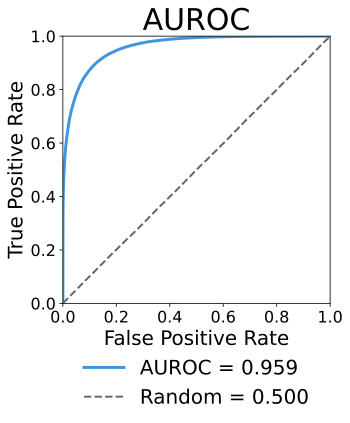

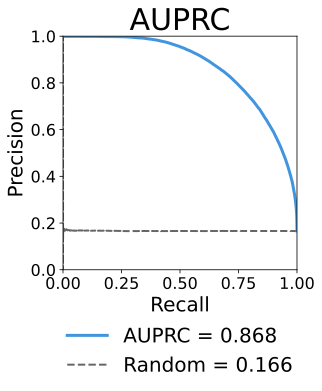

In [ ]:
score_threshold = 0.5

# Plot roc curve with scores and labels
accuracy = accuracy_score(all_labels_flat, all_scores_flat > score_threshold)
precision = precision_score(all_labels_flat, all_scores_flat > score_threshold)
recall = recall_score(all_labels_flat, all_scores_flat > score_threshold)
f1 = f1_score(all_labels_flat, all_scores_flat > score_threshold)
auprc = average_precision_score(all_labels_flat, all_scores_flat)
auroc = roc_auc_score(all_labels_flat, all_scores_flat)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Average Precision: {auprc:.4f}")
print(f"ROC AUC: {auroc:.4f}")

tf_dna_roc_fig, tf_dna_roc_ax = tf_dna_binding_roc_plot(
    all_scores_flat=all_scores_flat,
    all_labels_flat=all_labels_flat,
    method_color_dict=method_color_dict,
)

tf_dna_prc_fig, tf_dna_prc_ax = tf_dna_binding_prc_plot(
    all_scores_flat=all_scores_flat,
    all_labels_flat=all_labels_flat,
    method_color_dict=method_color_dict,
)

tf_dna_plots = PROJECT_DIR / "new_plots" / "tf_dna_binding_evaluation"
tf_dna_plots.mkdir(parents=True, exist_ok=True)

tf_dna_roc_fig_path = tf_dna_plots / f"roc_{cell_type}_tf_dna_vs_test_set.png"
tf_dna_prc_fig_path = tf_dna_plots / f"prc_{cell_type}_tf_dna_vs_test_set.png"

tf_dna_roc_fig.savefig(
    tf_dna_roc_fig_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15,
)

tf_dna_prc_fig.savefig(
    tf_dna_prc_fig_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.15,
)

# Model Evaluation

### Load WandB Training Logs

In [ ]:
import wandb
api = wandb.Api()

run_id = "f7ratf2t"

run = api.run(f"luminarada-penn-state-health/celltype-TF-TG/{run_id}")

# Load the final summary metrics from the run
training_summary = pd.DataFrame.from_dict(run.summary_metrics, orient="index").reset_index().rename(columns={"index": "Metric", 0: "Value"})
display(training_summary)

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /gpfs/Home/esm5360/.netrc.


,Metric,Value
0,_runtime,5364
1,_step,854
2,_timestamp,1790965712.163393
3,_wandb.runtime,5364
4,epoch,10
...,...,...
718,val/sample/young_rep2/auprc,0.678945
719,val/sample/young_rep2/auroc,0.792624
720,val/sample/young_rep2/celltype/HSC/acc,0.759956
721,val/sample/young_rep2/celltype/HSC/auprc,0.678945


In [ ]:
# Load the run training history
rows = run.scan_history(
    page_size=10_000,
)
run_history = pd.DataFrame(rows)

In [ ]:
sample_list = {}
for dataset_item in run.config["dataset"]:
    sample_items = dataset_item.split(":")
    tissue, sample = sample_items[0], sample_items[1]
    if "tissue" not in sample_list:
        sample_list["tissue"] = []
    if "sample" not in sample_list:
        sample_list["sample"] = []
    sample_list["tissue"].append(tissue)
    sample_list["sample"].append(sample)

holdout_celltypes = run.config["holdout_celltype"]
holdout_samples = run.config["holdout_sample"]


def print_celltypes_used_in_split(sample_list, run, split_name="train"):
    for tissue, sample in zip(sample_list["tissue"], sample_list["sample"]):
        print(f"  - {tissue}: {sample}")
        
        celltypes_key = f"{tissue}__{sample}_{split_name}_celltypes"
        
        if celltypes_key not in run.config:
            print("    - None")
        else:
            split_celltypes = run.config.get(celltypes_key, "None")
            for celltype in split_celltypes:
                print(f"    - {celltype}")

print("Samples used for training:")
for tissue, sample in zip(sample_list["tissue"], sample_list["sample"]):
    print(f"  - {sample}")

# print(f"Cell Types Used for Training:")
# print_celltypes_used_in_split(sample_list, run, "train")

print("\nHeld-out cell types and samples:")    
print(f"  - Held-out cell types: {holdout_celltypes}")
print(f"  - Held-out samples: {holdout_samples}")

print(f"\nCell Types Used for Validation:")
print_celltypes_used_in_split(sample_list, run, "val")

print(f"\nCell Types Used for Testing:")
print_celltypes_used_in_split(sample_list, run, "test")
    


Samples used for training:
  - E7.5_rep1
  - E7.5_rep2
  - E8.0_rep1
  - E8.0_rep2
  - E8.5_rep1
  - E8.5_rep2
  - Ctrl_4weeks_1
  - Ctrl_4weeks_2
  - Ctrl_6months_1
  - skin_late_anagen
  - brain
  - brain
  - young_rep1
  - young_rep2
  - old_rep1
  - old_rep2
  - liver_sample

Held-out cell types and samples:
  - Held-out cell types: ['B cells', 'Endothelial', 'Fibroblasts']
  - Held-out samples: ['mouse_liver:liver_sample']

Cell Types Used for Validation:
  - mESC: E7.5_rep1
    - Blood_progenitors
    - Epiblast_lineage
    - ExE_ectoderm
    - ExE_endoderm_lineage
    - Intermediate_mesoderm
    - Mesenchyme
    - Mesoderm_lineage
    - Neurectoderm
    - Surface_ectoderm
  - mESC: E7.5_rep2
    - Blood_progenitors
    - Epiblast_lineage
    - ExE_ectoderm
    - ExE_endoderm_lineage
    - Forebrain_Midbrain_Hindbrain
    - Intermediate_mesoderm
    - Mesenchyme
    - Mesoderm_lineage
    - Neurectoderm
    - Spinal_cord
    - Surface_ectoderm
  - mESC: E8.0_rep1
    - Blood_prog

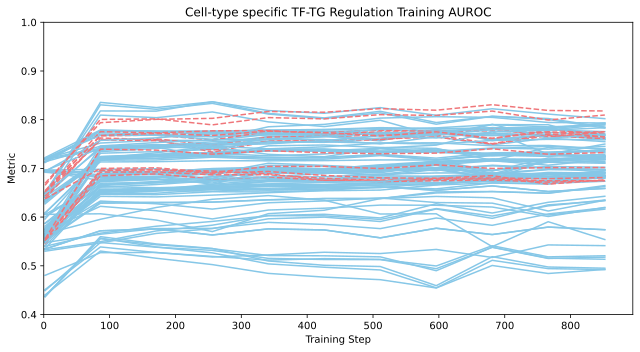

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(figsize=(9, 5))

split = "val"
color_by_holdout = True
style_by_holdout = True

celltype_metric_name_map = {}
for tissue, sample in zip(sample_list["tissue"], sample_list["sample"]):
    split_celltypes = run.config[f"{tissue}__{sample}_{split}_celltypes"]
    
    split_metric_naming_convention = f"{split}/sample/{sample}/celltype/{{celltype}}/auroc"
    for celltype in split_celltypes:
        celltype_metric_name_map[(tissue, split, sample, celltype)] =  split_metric_naming_convention.format(celltype=celltype)

for (tissue, split, sample, celltype), metric_name in celltype_metric_name_map.items():
    metric_history = (
        run_history[["_step", metric_name]]
        .dropna()
        .sort_values("_step")
    )
    

    if f"{tissue}:{sample}" in holdout_samples or celltype in holdout_celltypes:
        color = "#EF767A" if color_by_holdout else None
        style = "--" if style_by_holdout else "-"
    else:
        color = "#86C7E7" if color_by_holdout else None
        style = "-" if style_by_holdout else "-"
    
    axes.plot(
        metric_history["_step"],
        metric_history[metric_name],
        label=f"{sample} {celltype}",
        color=color,
        linestyle=style,
    )

axes.set_title("Cell-type specific TF-TG Regulation Training AUROC")
axes.set_xlabel("Training Step")
axes.set_ylabel("Metric")
axes.set_ylim(0.4, 1)
axes.set_xlim(left=0)
# axes.legend(
#     bbox_to_anchor=(1.05, 0.5), 
#     loc='center left',
#     title="Cell-type Specific AUROC", 
#     title_fontproperties={'weight': 'bold'}, 
#     frameon=False,
#     ncols=2
# )

plt.tight_layout()

## Cross-trained model vs other inference methods

In [ ]:
import h5py
from collections import Counter
from joblib import Parallel, delayed

def load_run_config(model_checkpoint: Path):
    run_dir = model_checkpoint.parent.parent
    with open(run_dir / "run_config.json") as handle:
        return json.load(handle)


def load_celltype_ground_truth(gt_file_index, celltype):
    celltype_file_name = celltype.replace(" ", "_")

    gt_filename = f"{celltype_file_name}_ground_truth.parquet"
    gt_path = gt_file_index.get(gt_filename)

    if gt_path is None:
        print(f"No ground truth found for {celltype}")
        return None

    # Load and prepare this cell type's GT once.
    # Note: GT is already filtered to TFs with embeddings
    gt = pd.read_parquet(
        gt_path,
        columns=["Source", "Target"],
    )

    gt = (
        gt.assign(
            Source=gt["Source"].astype(str).str.upper(),
            Target=gt["Target"].astype(str).str.upper(),
        )
        .drop_duplicates(["Source", "Target"])
    )

    return gt


def normalize_pairs(df):
    """
    Normalize the Source and Target columns in the DataFrame.
    """
    df = df.dropna(subset=["Source", "Target"]).copy()
    for col in ["Source", "Target"]:
        df[col] = df[col].astype(str).str.strip().str.upper()
    return df


def generate_edge_universe_from_gt(gt):
    """
    Generate a universe of all possible edges from the ground truth.
    """

    gt = normalize_pairs(gt).drop_duplicates(["Source", "Target"])

    universe = pd.MultiIndex.from_product(
        [
            sorted(gt["Source"].unique()),
            sorted(gt["Target"].unique()),
        ],
        names=["Source", "Target"],
    ).to_frame(index=False)

    positive_pairs = pd.MultiIndex.from_frame(gt[["Source", "Target"]])
    candidate_pairs = pd.MultiIndex.from_frame(universe[["Source", "Target"]])
    universe["_in_gt"] = candidate_pairs.isin(positive_pairs).astype("int8")
    return universe


def sample_auprc_10x_negatives(full_universe, random_state=42):
    """Keep all positives, sample negatives at 10x the positive count."""
    positives = full_universe[full_universe["_in_gt"] == 1]
    negatives = full_universe[full_universe["_in_gt"] == 0]

    n_pos = len(positives)
    n_neg_sample = min(n_pos * 10, len(negatives))

    if n_pos == 0 or n_neg_sample == 0:
        return full_universe.iloc[0:0].copy()

    neg_sampled = negatives.sample(
        n=n_neg_sample,
        replace=False,
        random_state=random_state,
    )

    auprc_df = pd.concat([positives, neg_sampled], axis=0)
    auprc_df = auprc_df.sample(frac=1.0, random_state=random_state).reset_index(drop=True)

    return auprc_df


def filter_df_to_gene_set(df, gene_set1, gene_set2):
    df = df.copy()
    df = df[
        df["Source"].isin(gene_set1) & df["Target"].isin(gene_set2)
    ]
    return df


def label_grn_with_universe(grn, universe, missing_score=np.nan):
    predictions = normalize_pairs(grn[["Source", "Target", "Score"]])
    # Absolute scores: signed methods (e.g. regression coefficients) rank by strength.
    predictions["Score"] = pd.to_numeric(predictions["Score"], errors="coerce").abs()
    predictions = predictions.loc[np.isfinite(predictions["Score"])].copy()

    # Keep the maximum score for duplicate TF-TG pairs.
    predictions = predictions.groupby(["Source", "Target"], as_index=False)["Score"].max()

    labeled = universe[["Source", "Target", "_in_gt"]].merge(
        predictions,
        on=["Source", "Target"],
        how="left",
        validate="one_to_one",
    )
    labeled["Score"] = labeled["Score"].fillna(missing_score)
    labeled = labeled.dropna(subset=["Score"])

    return labeled


def generate_hash_key(sample_celltype_df, other_method_names, model_run_dict):
    # Create a hash of the sample, cell type, and method lists
    rows = [
        {
            "sample": str(sample),
            "eval_type": str(eval_type),
            "celltypes": sorted(set(map(str, celltypes))),
            "model_names": sorted(model_run_dict.values())
        }
        for sample, eval_type, celltypes
        in sample_celltype_df.itertuples(index=False, name=None)
    ]

    payload = {
        "rows": sorted(rows, key=lambda row: json.dumps(row, sort_keys=True)),
        "other_methods": sorted(set(map(str, other_method_names))),
        # The cache holds one labeled GRN per model and one for the mean over the models.
        "model_grn_keys": "per_model_and_mean",
    }

    canonical = json.dumps(payload, sort_keys=True, separators=(",", ":"))
    hash_key = hashlib.sha256(canonical.encode("utf-8")).hexdigest()[:8]

    return hash_key


def read_sample_genes(data_path):
    """Read only the RNA gene names from the .h5mu, not the expression matrix."""
    with h5py.File(data_path, "r") as f:
        var = f["mod/rna/var"]
        names = var[var.attrs["_index"]][:]
    return {(n.decode() if isinstance(n, bytes) else str(n)).upper() for n in names}


def label_one_celltype(sample_name, celltype, sample_genes, model_grns,
                       gt_file_index, other_method_grn_dir, other_method_names,
                       other_method_sample):
    """Load, filter, and label every method's GRN for one (sample, cell type).

    other_method_sample is the sample name in the other-method GRN file names,
    or None when the other methods were not run on this sample.
    """
    messages, celltype_results = [], {}

    celltype_gt = load_celltype_ground_truth(gt_file_index, celltype)
    if celltype_gt is None:
        messages.append(f"{sample_name} / {celltype}: no ground truth found")
        return sample_name, celltype, None, celltype_results, messages

    celltype_gt = filter_df_to_gene_set(celltype_gt, sample_genes, sample_genes)
    if celltype_gt.empty:
        messages.append(f"{sample_name} / {celltype}: ground truth has no edges in sample; skipping")
        return sample_name, celltype, None, celltype_results, messages
    celltype_gt = normalize_pairs(celltype_gt).drop_duplicates(["Source", "Target"])

    full_universe = generate_edge_universe_from_gt(celltype_gt)
    auprc_eval_universe = sample_auprc_10x_negatives(full_universe)
    if auprc_eval_universe["_in_gt"].nunique() < 2:
        messages.append(f"{sample_name} / {celltype}: AUPRC universe lacks positives or negatives")

    # model_grns is keyed by (model name, eval type). MEAN_MODEL is the mean score over the models.
    for model_key, model_grn in model_grns.items():
        model_grn = filter_df_to_gene_set(model_grn, sample_genes, sample_genes)
        celltype_results[model_key] = {
            "full_universe": label_grn_with_universe(model_grn, full_universe),
            "auprc_universe": label_grn_with_universe(model_grn, auprc_eval_universe),
        }

    if other_method_sample is None:
        messages.append(f"{sample_name} / {celltype}: no other-method GRNs for this sample")
        return sample_name, celltype, celltype_gt, celltype_results, messages

    for other_method_name in other_method_names:
        celltype_results[other_method_name] = {}
        grn_filename = f"{other_method_name.lower().replace('_', '')}_{celltype.replace(' ', '_')}_{other_method_sample}.tsv"
        grn_path = other_method_grn_dir / other_method_name / grn_filename
        if not grn_path.exists():
            messages.append(f"{sample_name} / {celltype}: no {other_method_name} GRN found")
            continue

        grn = pd.read_csv(grn_path, sep="\t", usecols=["Source", "Target", "Score"], engine="pyarrow")

        full = label_grn_with_universe(grn, full_universe)
        full["Score"] = (full["Score"] - full["Score"].min()) / (full["Score"].max() - full["Score"].min())
        celltype_results[other_method_name] = {
            "full_universe": full,
            "auprc_universe": label_grn_with_universe(grn, auprc_eval_universe),
        }

    return sample_name, celltype, celltype_gt, celltype_results, messages


def load_grns_from_model_run(model_checkpoint, uid_of):
    # Use the GRNs written by generate_grns_from_model.py: the test set GRN of the
    # training samples, and one cross GRN for each holdout sample of the run.
    # uid_of maps (tissue, sample) to the unique SampleID used in this notebook.
    from scripts.generate_grns_from_model import holdout_grn_paths

    # Load the run config for the model
    model_run_dir = model_checkpoint.parent.parent
    run_config = load_run_config(model_checkpoint)

    # Determine the holdout GRN files for this model run
    holdout_specs = [
        tuple(spec.split(":", 1)) for spec in run_config.get("holdout_sample", [])
    ]
    holdout_grn_files = holdout_grn_paths(model_run_dir, holdout_specs)
    
    test_set_grn_file = model_run_dir / "test_set_grn.csv"
    missing_grn_files = [
        path for path in [test_set_grn_file, *holdout_grn_files.values()] if not path.is_file()
    ]
    if missing_grn_files:
        raise FileNotFoundError(
            f"Run generate_grns_from_model.py --run_dir {model_run_dir.name} first. Missing: "
            + ", ".join(path.name for path in missing_grn_files)
        )

    # Load the test set GRN
    self_trained_grn = pd.read_csv(test_set_grn_file, engine="pyarrow")


    # Remove any edges involving holdout cell types from the self-trained GRN
    holdout_cts = set(run_config.get("holdout_celltype", []))
    self_trained_grn = self_trained_grn[~self_trained_grn["CellType"].isin(holdout_cts)].copy()

    # Load the cross-trained GRNs for each holdout sample
    cross_grns = []
    for (tissue, sample), path in holdout_grn_files.items():
        grn = pd.read_csv(path, engine="pyarrow")
        grn["SampleID"] = uid_of[(tissue, RENAMED_SAMPLES.get((tissue, sample), sample))]
        cross_grns.append(grn)

    # Add the sample IDs to the self-trained GRN based on the tissue and sample mapping
    self_trained_grn["SampleID"] = [
        uid_of[(t, RENAMED_SAMPLES.get((t, s), s))]
        for t, s in zip(self_trained_grn["Tissue"], self_trained_grn["SampleID"])
    ]
    self_trained_grn = self_trained_grn.drop(columns="Tissue")

    # Concatenate the cross-trained GRNs for each holdout sample
    evaluation_grn = (
        pd.concat(cross_grns, ignore_index=True) if cross_grns
        else self_trained_grn.iloc[0:0].copy()
    )

    print(
        f"Self-trained GRN: {len(self_trained_grn):,} edges from "
        f"{sorted(self_trained_grn['SampleID'].unique())}"
    )
    print(
        f"Cross-trained GRN: {len(evaluation_grn):,} edges from "
        f"{sorted(evaluation_grn['SampleID'].unique())}"
    )

    return self_trained_grn, evaluation_grn



# Model name of the GRN with the mean edge score over all models in model_run_dict
MEAN_MODEL = "mean"


def mean_over_models(grn):
    """One row per (sample, cell type, edge), with the mean score of the models that predicted it."""
    return grn.groupby(
        ["SampleID", "CellType", "Source", "Target"], as_index=False, observed=True, sort=False,
    )["Score"].mean()

species = "mm10"

data_dir = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/data")

# A sample keeps its own name unless another tissue has a sample with the same
# name; then it becomes <tissue>__<sample>, as in holdout_grn_paths.
found = [
    (tissue_dir.name, path.parent.name, path)
    for tissue_dir in (data_dir / "processed").iterdir()
    for path in tissue_dir.rglob("*/multiome_processed.h5mu")
]
name_counts = Counter(sample for _, sample, _ in found)

sample_sources = {}   # unique ID -> where the sample's data is
for tissue, sample, path in found:
    uid = sample if name_counts[sample] == 1 else f"{tissue}__{sample}"
    sample_sources[uid] = {"tissue": tissue, "sample": sample, "h5mu": path}

# Create a (tissue, sample) map to the unique sample ID for each sample
uid_of = {(src["tissue"], src["sample"]): uid for uid, src in sample_sources.items()}

# Create a mapping from unique sample ID to tissue
sample_to_tissue_map = {uid: src["tissue"] for uid, src in sample_sources.items()}

# Runs trained before the 2026-10 rename still name both brain samples "brain".
RENAMED_SAMPLES = {
    ("GSE140203_shareseq", "brain"): "shareseq_brain",
    ("10x_E18_mouse_brain", "brain"): "E18_brain",
}

# Other-method GRN files use the renamed sample names, so no overrides are needed.
OTHER_METHOD_SAMPLE = {}

# Load and concatenate the self-trained and cross-trained GRNs for each model
model_self_grn_list = []
model_cross_grn_list = []
for model_name, run_name in model_run_dict.items():
    model_checkpoint = CHKPT_DIR / "celltype_tf_tg" / run_name / "checkpoints" / "last.ckpt"
    model_self_grn, model_cross_grn = load_grns_from_model_run(model_checkpoint, uid_of)
    
    model_self_grn["ModelName"] = model_name
    model_cross_grn["ModelName"] = model_name

    model_self_grn_list.append(model_self_grn)
    model_cross_grn_list.append(model_cross_grn)

self_trained_grn = pd.concat(model_self_grn_list, ignore_index=True)
evaluation_grn = pd.concat(model_cross_grn_list, ignore_index=True)

self_trained_grn["EvalType"] = SELF_MODEL_METHOD
evaluation_grn["EvalType"] = CROSS_MODEL_METHOD

# Combine the self-trained and cross-trained GRNs into a single DataFrame
sample_celltype_df = pd.concat([
    evaluation_grn[["EvalType", "SampleID", "CellType"]].drop_duplicates(),
    self_trained_grn[["EvalType", "SampleID", "CellType"]].drop_duplicates()
])

sample_celltype_df = sample_celltype_df.groupby(["SampleID", "EvalType"])["CellType"].apply(list).reset_index()

cell_type_specific_gt_dir = (
    DATA_DIR / "ground_truth_files" / "cell_type_specific"
)

# Directory containing the GRNs for other methods
other_method_grn_dir = Path(
    "/gpfs/Labs/Uzun/DATA/PROJECTS/"
    "2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/"
    "formatted_GRNs_celltype"
)

other_method_dirs = sorted(
    path for path in other_method_grn_dir.iterdir()
    if path.is_dir()
)

other_method_names = [method_dir.name for method_dir in other_method_dirs]

species_gt_dir = cell_type_specific_gt_dir / species
gt_file_index = {path.name: path for path in species_gt_dir.rglob("*_ground_truth.parquet")}


hash_key = generate_hash_key(sample_celltype_df, other_method_names, model_run_dict)

# Cache the method GRN dictionary and cell type ground truth dictionary in the
# testing_results directory. This allows for caching dictionaries with multiple models.
method_dict_file = testing_result_dir / f"all_method_grn_dict_{hash_key}.pkl"

# Try to load the method_grn_dict from the cache
requires_regen = True
if method_dict_file.is_file():
    try:
        with open(method_dict_file, "rb") as f:
            cached = pickle.load(f)
        method_grn_dict = cached["method_grn_dict"]
        celltype_gt_dict = cached["celltype_gt_dict"]
        requires_regen = False
    except Exception as e:
        logging.warning(f"Error loading cache: {e}")
        os.remove(method_dict_file)

if requires_regen:
    logging.warning("Cache is incomplete. Re-generating...")

    # Split each model GRN once, so each worker receives only its own slice.
    # Each (sample, cell type) gets the GRN of every model that predicted it,
    # keyed (model name, eval type), plus the mean score over those models.
    model_slices = {}
    for eval_type, grn in {SELF_MODEL_METHOD: self_trained_grn, CROSS_MODEL_METHOD: evaluation_grn}.items():
        for (sample, celltype), sub in mean_over_models(grn).groupby(["SampleID", "CellType"], sort=False, observed=True):
            model_slices.setdefault((sample, celltype), {})[(MEAN_MODEL, eval_type)] = sub
        for (model_name, sample, celltype), sub in grn.groupby(["ModelName", "SampleID", "CellType"], sort=False, observed=True):
            model_slices.setdefault((sample, celltype), {})[(model_name, eval_type)] = sub

    # Read each sample's gene names once.
    sample_genes_dict = {}
    for sample_name in {sample for sample, _ in model_slices}:
        assert sample_name in sample_sources, f"No processed data for sample: {sample_name}"
        sample_genes_dict[sample_name] = read_sample_genes(sample_sources[sample_name]["h5mu"])
        logging.info(f"{sample_name}: {len(sample_genes_dict[sample_name])} genes")

    n_jobs = min(len(model_slices), len(os.sched_getaffinity(0)))
    outputs = Parallel(n_jobs=n_jobs, backend="loky", verbose=10)(
        delayed(label_one_celltype)(
            sample_name, celltype, sample_genes_dict[sample_name], model_grns,
            gt_file_index, other_method_grn_dir, other_method_names,
            OTHER_METHOD_SAMPLE.get(sample_name, sample_sources[sample_name]["sample"]),
        )
        for (sample_name, celltype), model_grns in model_slices.items()
    )

    method_grn_dict, celltype_gt_dict = {}, {}
    for sample_name, celltype, gt, results, messages in outputs:
        for message in messages:
            logging.warning(message)
        method_grn_dict.setdefault(sample_name, {})[celltype] = results
        if gt is not None:
            celltype_gt_dict.setdefault(sample_name, {})[celltype] = gt

    with open(method_dict_file, "wb") as f:
        pickle.dump({"method_grn_dict": method_grn_dict, "celltype_gt_dict": celltype_gt_dict}, f)


NameError: name 'Path' is not defined

### Calculate performance metrics

In [ ]:
from scipy.stats import hypergeom
from sklearn.metrics import roc_auc_score


def _safe_divide(numerator, denominator):
    if denominator == 0:
        return np.nan
    return float(numerator / denominator)


def _benjamini_hochberg(p_values):
    """Return Benjamini-Hochberg adjusted p-values without statsmodels."""
    p_values = np.asarray(p_values, dtype=float)
    if p_values.size == 0:
        return np.array([], dtype=float)

    order = np.argsort(p_values, kind="stable")
    ranked_p = p_values[order]
    ranks = np.arange(1, len(ranked_p) + 1, dtype=float)

    ranked_q = ranked_p * len(ranked_p) / ranks
    ranked_q = np.minimum.accumulate(ranked_q[::-1])[::-1]
    ranked_q = np.clip(ranked_q, 0.0, 1.0)

    q_values = np.empty_like(ranked_q)
    q_values[order] = ranked_q
    return q_values


def _pr_auc_integral(labels, scores):
    """
    AUPRC with continuous interpolation between PR points.

    Matches PRROC ``pr.curve(...)$auc.integral`` (checked against PRROC 1.4,
    including heavily tied scores). Between two PR points, FP grows linearly
    with TP, so precision(x) = x / (a*x + b) and each segment integrates exactly.
    """
    labels = np.asarray(labels, dtype=bool)
    scores = np.asarray(scores, dtype=float)
    n_pos = labels.sum()
    if n_pos == 0 or n_pos == len(labels):
        return np.nan

    order = np.argsort(-scores, kind="stable")
    sorted_scores = scores[order]
    sorted_labels = labels[order]

    # Cumulative TP/FP at the end of each group of tied scores.
    last_of_tie = np.r_[sorted_scores[1:] != sorted_scores[:-1], True]
    tp = np.r_[0, np.cumsum(sorted_labels)[last_of_tie]].astype(float)
    fp = np.r_[0, np.cumsum(~sorted_labels)[last_of_tie]].astype(float)

    tp0, tp1, fp0, fp1 = tp[:-1], tp[1:], fp[:-1], fp[1:]
    keep = tp1 > tp0
    tp0, tp1, fp0, fp1 = tp0[keep], tp1[keep], fp0[keep], fp1[keep]

    slope = (fp1 - fp0) / (tp1 - tp0)
    a = 1.0 + slope
    b = fp0 - slope * tp0

    def antiderivative(x):
        with np.errstate(divide="ignore", invalid="ignore"):
            log_term = np.where(b != 0, (b / a**2) * np.log(a * x + b), 0.0)
        return x / a - log_term

    area = antiderivative(tp1) - antiderivative(tp0)
    return float(area.sum() / n_pos)


def _sample_10x_negatives(labels, rng):
    """Indices of all positives plus 10x as many randomly sampled negatives."""
    pos_idx = np.flatnonzero(labels == 1)
    neg_idx = np.flatnonzero(labels == 0)
    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return np.array([], dtype=np.int64)
    neg_idx = rng.choice(neg_idx, size=min(10 * len(pos_idx), len(neg_idx)), replace=False)
    return np.r_[pos_idx, neg_idx]


def compute_metrics(
    method_name: str,
    sample_name: str,
    celltype: str,
    labeled_df: pd.DataFrame,
    celltype_gt: pd.DataFrame,
    universe: pd.DataFrame,
    top_k_edges: int | None = None,
    top_fraction: float = 0.10,
    ptf_alpha: float = 0.05,
    random_state: int = 42,
    return_curve_data: bool = False,
):
    """
    Calculate ranking and top-edge GRN metrics for one method, sample, and
    cell type, following the benchmark paper's accuracy assessment.

    Inputs
    ------
    labeled_df : output of ``label_grn_with_universe``. One row per predicted
        pair in the universe, with Source, Target, _in_gt, and |Score|.
    celltype_gt : the cell type's GT edges (Source, Target), filtered to the
        sample's genes.
    universe : ``generate_edge_universe_from_gt(celltype_gt)``, every GT TF x
        every GT target with its _in_gt label.

    Ranking metrics
    ---------------
    AUROC : predicted edges only, with positives and negatives sampled 1:1.
    AUPRC : the complete universe U, with unpredicted pairs scored 0, all
        positives, and 10x as many sampled negatives. Uses the PRROC integral.
    Random AUPRC : the same, with uniform random scores over U.

    With ``return_curve_data=True``, also returns the labels and scores of the
    exact AUROC and AUPRC samples, for plotting ROC and PR curves.

    Set definitions
    ---------------
    A : the method's ``top_k_edges`` highest-scoring edges (10k in the paper),
        or its top ``top_fraction`` if ``top_k_edges`` is None
    B : GT edges
    U : every GT TF x every GT target

    A is the predicted-positive set for every binary metric (precision,
    recall, F1, accuracy, FPR, Jaccard, PerInt, EPR, and predictable TFs).
    No score cutoff is used, so methods with different score scales are
    compared on their most confident edges.
    """
    rng = np.random.default_rng(random_state)

    if top_k_edges is None and not 0 < top_fraction <= 1:
        raise ValueError(f"top_fraction must be in the interval (0, 1]. Got {top_fraction}")
    if top_k_edges is not None and top_k_edges <= 0:
        raise ValueError(f"top_k_edges must be > 0. Got {top_k_edges}")

    # U is the full GT TF x GT target grid, so every TF has the same candidate targets.
    gt_out_degree = celltype_gt.groupby("Source")["Target"].nunique()
    n_gt_targets = celltype_gt["Target"].nunique()
    n_universe = len(gt_out_degree) * n_gt_targets
    n_ground_truth_edges = len(celltype_gt)

    # Rank the predicted edges. Ties keep the universe order.
    df = labeled_df.sort_values("Score", ascending=False, kind="stable").reset_index(drop=True)
    labels = df["_in_gt"].astype(int).to_numpy()
    scores = df["Score"].astype(float).to_numpy()

    n_edges = len(df)
    n_pos = int(labels.sum())
    has_both_classes = 0 < n_pos < n_edges

    # ------------------------------------------------------------------
    # Top-edge set A.
    # ------------------------------------------------------------------
    if top_k_edges is not None:
        top_k = min(top_k_edges, n_edges)
    else:
        top_k = min(n_edges, max(1, int(round(top_fraction * n_edges))))
    top_df = df.head(top_k)

    early_precision = float(top_df["_in_gt"].mean()) if top_k else np.nan
    epr = _safe_divide(early_precision, n_pos / n_edges) if n_edges else np.nan

    # ------------------------------------------------------------------
    # AUROC: predicted edges only, balanced 1:1 by downsampling the larger class.
    # ------------------------------------------------------------------
    roc_labels = roc_scores = np.array([])
    if has_both_classes:
        pos_idx = np.flatnonzero(labels == 1)
        neg_idx = np.flatnonzero(labels == 0)
        n_balanced = min(len(pos_idx), len(neg_idx))
        balanced_idx = np.r_[
            rng.choice(pos_idx, size=n_balanced, replace=False),
            rng.choice(neg_idx, size=n_balanced, replace=False),
        ]
        roc_labels, roc_scores = labels[balanced_idx], scores[balanced_idx]
        auroc = roc_auc_score(roc_labels, roc_scores)
        random_auroc = roc_auc_score(roc_labels, rng.random(len(balanced_idx)))
    else:
        auroc = random_auroc = np.nan

    # ------------------------------------------------------------------
    # AUPRC: complete universe, unpredicted pairs scored 0, 1:10 negatives.
    # ------------------------------------------------------------------
    universe_scores = (
        universe[["Source", "Target", "_in_gt"]]
        .merge(df[["Source", "Target", "Score"]], on=["Source", "Target"], how="left", validate="one_to_one")
    )
    universe_labels = universe_scores["_in_gt"].to_numpy(dtype=int)
    universe_score_values = universe_scores["Score"].fillna(0.0).to_numpy(dtype=float)

    pr_idx = _sample_10x_negatives(universe_labels, rng)
    pr_labels, pr_scores = universe_labels[pr_idx], universe_score_values[pr_idx]
    auprc = _pr_auc_integral(pr_labels, pr_scores) if len(pr_idx) else np.nan

    random_idx = _sample_10x_negatives(universe_labels, rng)
    random_auprc = (
        _pr_auc_integral(universe_labels[random_idx], rng.random(len(random_idx)))
        if len(random_idx) else np.nan
    )

    # ------------------------------------------------------------------
    # Binary network metrics: A vs B within U.
    # ------------------------------------------------------------------
    tp = int(top_df["_in_gt"].sum())
    fp = top_k - tp
    fn = n_ground_truth_edges - tp
    tn = n_universe - n_ground_truth_edges - fp

    if tn < 0:
        raise ValueError(
            f"Computed a negative TN count for {method_name}/{sample_name}/{celltype}. "
            "Check that labeled_df and celltype_gt come from the same universe."
        )

    jaccard_index = _safe_divide(tp, tp + fp + fn)
    perint = 100.0 * _safe_divide(tp, min(top_k, n_ground_truth_edges))
    top_edge_recall = _safe_divide(tp, tp + fn)
    top_edge_fpr = _safe_divide(fp, fp + tn)

    # A is the predicted-positive set; everything else in U is predicted negative.
    precision = early_precision
    f1 = _safe_divide(2 * tp, 2 * tp + fp + fn)
    accuracy = _safe_divide(tp + tn, n_universe)

    # ------------------------------------------------------------------
    # Predictable TFs: one-sided hypergeometric enrichment of each TF's
    # targets in A, then Benjamini-Hochberg across the TFs in A.
    # ------------------------------------------------------------------
    top_by_tf = (
        top_df.groupby("Source")["_in_gt"]
        .agg(n_predicted="size", n_overlap="sum")
        .join(gt_out_degree.rename("n_true"), how="inner")
    )
    ptf_p_values = np.asarray(
        hypergeom.sf(
            top_by_tf["n_overlap"].to_numpy() - 1,
            n_gt_targets,
            top_by_tf["n_true"].to_numpy(),
            top_by_tf["n_predicted"].to_numpy(),
        ),
        dtype=float,
    )
    ptf_q_values = _benjamini_hochberg(ptf_p_values)

    n_evaluable_tfs = len(ptf_p_values)
    predictable_tfs = int(np.sum(ptf_q_values < ptf_alpha))
    predictable_tfs_raw_p = int(np.sum(ptf_p_values < ptf_alpha))
    predictable_tf_fraction = _safe_divide(predictable_tfs, n_evaluable_tfs)

    metrics_df = pd.DataFrame([{
        "method_name": method_name,
        "sample_name": sample_name,
        "cell_type": celltype,
        "auroc": auroc,
        "rand_auroc": random_auroc,
        "auprc": auprc,
        "rand_auprc": random_auprc,
        "early_precision": early_precision,
        "early_precision_rate": epr,
        "accuracy": accuracy,
        "precision": precision,

        # Binary metrics from the top-edge set A.
        "recall": top_edge_recall,
        "fpr": top_edge_fpr,
        "f1": f1,
        "jaccard_index": jaccard_index,
        "perint": perint,

        # Full predicted network
        "n_tfs": df["Source"].nunique(),
        "n_targets": df["Target"].nunique(),
        "n_edges": n_edges,

        # Top-edge network
        "top_n_tfs": top_df["Source"].nunique(),
        "top_n_targets": top_df["Target"].nunique(),
        "top_k_edges": top_k,
        "max_edges": top_k_edges,

        "top_fraction": top_fraction,
        "predictable_tfs": predictable_tfs,
        "predictable_tfs_raw_p": predictable_tfs_raw_p,
        "predictable_tf_fraction": predictable_tf_fraction,
        "n_evaluable_tfs": n_evaluable_tfs,
        "top_tp": tp,
        "top_fp": fp,
        "top_fn": fn,
        "top_tn": tn,
        "n_universe_pairs": n_universe,
        "n_pos": n_pos,
        "n_neg": n_edges - n_pos,
        "n_ground_truth_edges": n_ground_truth_edges,
        "ptf_alpha": ptf_alpha,
        "ptf_multiple_testing": "Benjamini-Hochberg FDR",
    }])

    if return_curve_data:
        curve_data = {
            "roc_labels": roc_labels.astype(np.int8),
            "roc_scores": roc_scores.astype(np.float32),
            "pr_labels": pr_labels.astype(np.int8),
            "pr_scores": pr_scores.astype(np.float32),
        }
        return metrics_df, curve_data
    return metrics_df


In [ ]:
from scripts.build_tf_to_tg_celltype_data import split_genes_by_chromosome

# Test-set chromosomes held out from training. These must match
# build_tf_to_tg_celltype_data.py, which hard-codes the split per species.
TEST_CHROMS = {"mm10": ["18", "19"], "hg38": ["20", "21", "22"]}
DEFAULT_GENE_REF_FILES = {
    "mm10": "Mus_musculus.GRCm39.115.gtf.gz",
    "hg38": "Homo_sapiens.GRCh38.113.gtf.gz",
}
# All six runs use the default gene annotation (gene_ref_file is null in their configs).
gene_ref_file = (
    data_dir / "genome_data" / "genome_annotation" / species / DEFAULT_GENE_REF_FILES[species]
)
_, _, test_genes = split_genes_by_chromosome(
    gene_ref_file, train_chroms=[], val_chroms=[], test_chroms=TEST_CHROMS[species],
)
test_genes = set(test_genes)

metric_frames = []
curve_data = {}  # {(sample, cell type, method): labels/scores of the AUROC and AUPRC samples}
for sample_name, celltype_dict in method_grn_dict.items():
    for celltype, method_dict in celltype_dict.items():
        celltype_gt = celltype_gt_dict.get(sample_name, {}).get(celltype)
        if celltype_gt is None:
            continue
        universe = generate_edge_universe_from_gt(celltype_gt)

        for method_key, method_grns in method_dict.items():
            # Methods with no GRN file for this cell type have an empty entry.
            if "full_universe" not in method_grns:
                continue

            # TF-TG model GRNs are keyed (model name, eval type); other methods by method name.
            model_name, method_name = method_key if isinstance(method_key, tuple) else (None, method_key)

            # The self-trained model only predicts test-chromosome targets, so it is
            # scored on the test-chromosome universe. All other methods use all chromosomes.
            use_test_chroms = method_name == SELF_MODEL_METHOD
            labeled_df = method_grns["full_universe"]
            if use_test_chroms:
                method_gt = celltype_gt[celltype_gt["Target"].isin(test_genes)]
                if method_gt.empty:
                    logging.warning(f"No test-chromosome GT edges for {celltype} in {sample_name}; skipping")
                    continue
                method_universe = generate_edge_universe_from_gt(method_gt)
                labeled_df = labeled_df[
                    labeled_df["Source"].isin(method_gt["Source"])
                    & labeled_df["Target"].isin(method_gt["Target"])
                ]
            else:
                method_gt, method_universe = celltype_gt, universe

            metrics_df, method_curve_data = compute_metrics(
                method_name=method_name,
                sample_name=sample_name,
                celltype=celltype,
                labeled_df=labeled_df,
                celltype_gt=method_gt,
                universe=method_universe,
                top_fraction=0.1,
                return_curve_data=True,
            )
            metrics_df["universe"] = "test_chromosomes" if use_test_chroms else "all_chromosomes"
            metrics_df["model_name"] = model_name
            metric_frames.append(metrics_df)

            # Keep the curves of the combined comparison only (mean model and other methods).
            if model_name in (None, MEAN_MODEL):
                curve_data[(sample_name, celltype, method_name)] = method_curve_data

# One row per (model, sample, cell type, method). model_name is MEAN_MODEL for the
# mean score over the models, a model_run_dict key for one model, and None for other methods.
all_model_metrics_df = pd.concat(metric_frames, ignore_index=True)

# Combined comparison: the mean-score model and the other methods
celltype_metrics_df = (
    all_model_metrics_df[all_model_metrics_df["model_name"].isna() | (all_model_metrics_df["model_name"] == MEAN_MODEL)]
    .drop(columns="model_name")
    .reset_index(drop=True)
)
display(celltype_metrics_df)

# Saved next to the labeled GRN cache, with the same hash of the samples and model runs.
celltype_metrics_path = testing_result_dir / f"celltype_metrics_{hash_key}.tsv"
celltype_metrics_df.to_csv(celltype_metrics_path, sep="\t", index=False)
all_model_metrics_df.to_csv(testing_result_dir / f"celltype_metrics_per_model_{hash_key}.tsv", sep="\t", index=False)


def metrics_for_model(model_name):
    """One model's metrics and the other methods' metrics on the same (sample, cell type) pairs."""
    model_rows = all_model_metrics_df[all_model_metrics_df["model_name"] == model_name]
    model_pairs = model_rows[["sample_name", "cell_type"]].drop_duplicates()
    other_rows = all_model_metrics_df[all_model_metrics_df["model_name"].isna()].merge(
        model_pairs, on=["sample_name", "cell_type"],
    )
    return pd.concat([model_rows, other_rows], ignore_index=True).drop(columns="model_name")


2026-10-12 09:49:34,170 - INFO - Splitting genes into train/val/test based on chromosome:
2026-10-12 09:50:10,495 - INFO - Extracted GTF attributes: ['gene_id', 'gene_version', 'gene_name', 'gene_source', 'gene_biotype', 'transcript_id', 'transcript_version', 'transcript_name', 'transcript_source', 'transcript_biotype', 'tag', 'transcript_support_level', 'exon_number', 'exon_id', 'exon_version', 'protein_id', 'protein_version', 'ccds_id']
2026-10-12 09:50:16,271 - INFO -   - Train set: 0 genes (chroms )
2026-10-12 09:50:16,291 - INFO -   - Validation set: 0 genes (chroms )
2026-10-12 09:50:16,337 - INFO -   - Test set: 4,099 genes (chroms 18-19)


,method_name,sample_name,cell_type,auroc,rand_auroc,auprc,rand_auprc,early_precision,early_precision_rate,accuracy,...,top_fp,top_fn,top_tn,n_universe_pairs,n_pos,n_neg,n_ground_truth_edges,ptf_alpha,ptf_multiple_testing,universe
0,TF-TG Model (self-trained),E7.5_rep1,Neurectoderm,0.688040,0.504418,0.542096,0.281235,0.650562,1.951686,0.743074,...,1150,8829,26720,38840,10970,21940,10970,0.05,Benjamini-Hochberg FDR,test_chromosomes
1,TF-TG Model (cross-trained),E7.5_rep1,Neurectoderm,0.666490,0.501462,0.516271,0.255735,0.627694,1.883083,0.763236,...,18068,134351,460879,643760,161766,323532,164813,0.05,Benjamini-Hochberg FDR,all_chromosomes
2,CellOracle,E7.5_rep1,Neurectoderm,0.529036,0.500956,0.260739,0.255968,0.321815,1.202792,0.741020,...,3631,163090,475316,643760,14325,39215,164813,0.05,Benjamini-Hochberg FDR,all_chromosomes
3,FigR,E7.5_rep1,Neurectoderm,0.488454,0.500685,0.267106,0.256190,0.285397,1.002721,0.735277,...,9332,161086,469615,643760,37170,93424,164813,0.05,Benjamini-Hochberg FDR,all_chromosomes
4,LINGER,E7.5_rep1,Neurectoderm,0.530359,0.500606,0.295143,0.256313,0.323980,1.140074,0.719020,...,30861,150023,448086,643760,129729,326783,164813,0.05,Benjamini-Hochberg FDR,all_chromosomes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
665,CellOracle,liver_sample,Endothelial,0.581637,0.501807,0.350006,0.367603,0.446362,1.563615,0.631295,...,738,25665,44612,71610,3805,9524,26260,0.05,Benjamini-Hochberg FDR,all_chromosomes
666,FigR,liver_sample,Endothelial,0.650616,0.494633,0.410066,0.367040,0.697118,1.858450,0.642271,...,494,25123,44856,71610,6118,10192,26260,0.05,Benjamini-Hochberg FDR,all_chromosomes
667,LINGER,liver_sample,Endothelial,0.589610,0.501392,0.471106,0.364071,0.615451,1.649700,0.651906,...,2220,22707,43130,71610,21538,36194,26260,0.05,Benjamini-Hochberg FDR,all_chromosomes
668,Pando,liver_sample,Endothelial,0.588843,0.599174,0.372320,0.365592,0.833333,1.028369,0.633403,...,2,26250,45348,71610,94,22,26260,0.05,Benjamini-Hochberg FDR,all_chromosomes


### Generate Plots

2026-10-12 10:26:57,492 - INFO - Using font: Arial


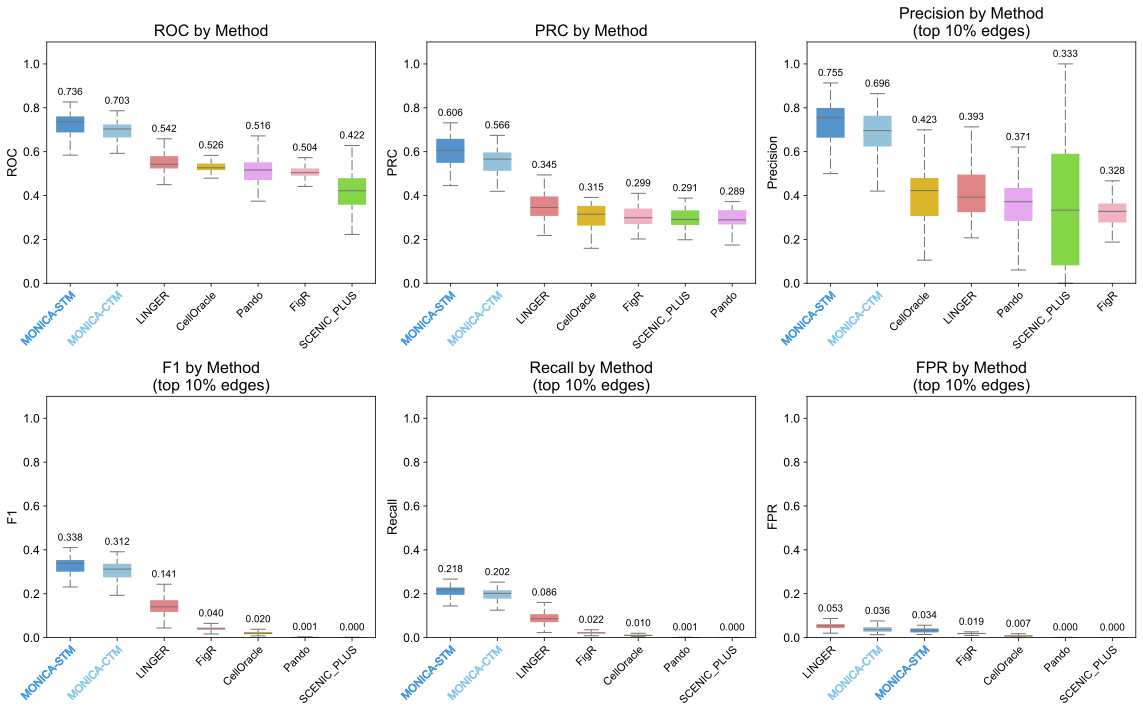

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns

import matplotlib.font_manager as fm
import matplotlib as mpl

font_path = PROJECT_DIR / "fonts" / "Arial.ttf"

fm.fontManager.addfont(font_path)
arial_font = fm.FontProperties(fname=font_path).get_name()

mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = [arial_font, "Helvetica", "Liberation Sans", "DejaVu Sans"]

logging.info(f"Using font: {arial_font}")

TFTG_MODEL_METHODS = {SELF_MODEL_METHOD, CROSS_MODEL_METHOD}


def _style_xticklabels(ax, originals, method_color_dict,
                       sample_rename_map=None, color_xticks=True,
                       rotation=45, fontsize=15):
    sample_rename_map = sample_rename_map or {}
    labels = [sample_rename_map.get(o, o) for o in originals]

    ax.set_xticks(range(len(originals)))
    ax.set_xticklabels(labels, rotation=rotation, ha="right",
                       fontsize=fontsize, rotation_mode="anchor")

    for tick, original in zip(ax.get_xticklabels(), originals):
        if original in TFTG_MODEL_METHODS:
            tick.set_fontsize(fontsize)
            if color_xticks:
                tick.set_color(method_color_dict.get(original, "black"))
            tick.set_path_effects([pe.withStroke(linewidth=0.6, foreground=tick.get_color())])
        else:
            tick.set_color("black")
            tick.set_fontweight("normal")


def plot_method_box_and_whisker(
    full_metric_df, 
    selected_column, 
    method_color_dict, 
    sample_rename_map, 
    show_values_above_boxes=True,
    title_suffix_str="",
    ):
    
    metric_ordered_by_auroc = (
        full_metric_df
        .groupby("method_name")[selected_column]
        .median()
        .sort_values(ascending=False)
        .index
        .tolist()
    )

    sanitized_name = selected_column.replace("_", " ").lower()
    if sanitized_name in ["auroc", "auprc"]:
        sanitized_name = sanitized_name.upper()
        sanitized_name = sanitized_name.replace("AU", "")
    else:
        sanitized_name = sanitized_name.capitalize()

    loosely_dashed = (5, (10, 3))
    
    fig = plt.figure(figsize=(7, 6))

    ax = sns.boxplot(
        data=full_metric_df, 
        x="method_name", 
        y=selected_column, 
        hue="method_name", 
        width=0.6,
        order=metric_ordered_by_auroc, 
        palette=method_color_dict,
        whiskerprops={"linestyle": loosely_dashed, "linewidth": 1},
        boxprops={"linewidth": 0},
        capprops={"linewidth": 1},
        medianprops={"linewidth": 1},
        showfliers=False
    )
    
    medians = (
        full_metric_df
        .groupby("method_name")[selected_column]
        .median()
        .reindex(metric_ordered_by_auroc)
    )

    for i, method in enumerate(metric_ordered_by_auroc):
        vals = full_metric_df.loc[full_metric_df["method_name"] == method, selected_column].dropna()
        if vals.empty:
            continue
        q1, q3 = vals.quantile([0.25, 0.75])
        top = vals[vals <= q3 + 1.5 * (q3 - q1)].max()

        if show_values_above_boxes:
            annotation = f"{vals.median():.3f}"
        else:
            ranks = medians.rank(method="min", ascending=False).astype(int)
            annotation = str(ranks[method])

        ax.text(i, top + 0.02, annotation, ha="center", va="bottom", fontsize=12)

    _style_xticklabels(
        ax,
        metric_ordered_by_auroc,
        method_color_dict=method_color_dict,
        sample_rename_map=sample_rename_map,
        color_xticks=True,
        rotation=45,
        fontsize=12
    )

    plt.title(f"{sanitized_name} by Method {title_suffix_str}", fontsize=17)
    plt.xlabel("")
    plt.ylabel(sanitized_name, fontsize=14)
    plt.yticks(fontsize=14)
    
    if full_metric_df[selected_column].max() > 1:
        plt.ylim((0, full_metric_df[selected_column].max() * 1.05))
    else:
        plt.ylim((0, 1.10))
    
    plt.tight_layout()
    
    return fig, ax



# One row per (sample, cell type, method).
full_metric_df = celltype_metrics_df

# Rename the TF-TG model methods on the x-axis.
sample_rename_map = method_display_name_map

# Use the same top-edge settings that compute_metrics used.
top_fraction = float(full_metric_df["top_fraction"].iloc[0])
# top_k_edges = int(full_metric_df["max_edges"].iloc[0])
top_k_mode = "fraction"

method_comparison_boxplot_dir = (
    PROJECT_DIR / "new_plots" / "model_vs_other_method_boxplots"
)
method_comparison_boxplot_dir.mkdir(parents=True, exist_ok=True)

# Selected columns by method box and whisker plot
methods = [
    "auroc", 
    "auprc", 
    "accuracy", 
    "early_precision", 
    "early_precision_rate",
    "precision", 
    "recall", 
    "fpr",
    "f1", 
    "perint", 
    "predictable_tf_fraction"
    ]

def save_method_boxplots(metric_df, out_dir, model_label="", show=True):
    """Save one method boxplot per metric in `methods` to out_dir."""
    out_dir.mkdir(parents=True, exist_ok=True)
    model_title_str = f"({model_label})" if model_label else ""

    boxplots = {}
    for selected_column in methods:

        sanitized_name = selected_column.replace("_", " ").lower()
        if sanitized_name in ["auroc", "auprc"]:
            sanitized_name = sanitized_name.upper()
            sanitized_name = sanitized_name.replace("AU", "")
        else:
            sanitized_name = sanitized_name.capitalize()

        if selected_column in ["early_precision", "early_precision_rate", "precision", "recall", "fpr", "f1", "accuracy", "perint", "predictable_tf_fraction"]:
            if top_k_mode == "fraction":
                title_suffix_str = f"{model_title_str}\n(top {int(top_fraction * 100)}% edges)"
            else:
                title_suffix_str = model_title_str
        else:
            title_suffix_str = model_title_str

        fig, ax = plot_method_box_and_whisker(
            metric_df,
            selected_column,
            method_color_dict,
            sample_rename_map,
            show_values_above_boxes=True,
            title_suffix_str=title_suffix_str
        )
        boxplots[selected_column] = (fig, ax)

        fig.savefig(
            out_dir / f"{sanitized_name.lower()}_by_method_boxplot.png",
            dpi=300,
            bbox_inches="tight"
        )

        if show:
            plt.show()
        else:
            plt.close(fig)

    return boxplots

def plot_selected_box_and_whisker_plots(
    full_metric_df,
    method_color_dict,
    sample_rename_map,
    show_values_above_boxes=True,
    title_suffix_str="",
    top_fraction=None,
):
    selected_columns = ["auroc", "auprc", "precision", "f1", "recall", "fpr"]

    metric_labels = {
        "auroc": "ROC",
        "auprc": "PRC",
        "precision": "Precision",
        "f1": "F1",
        "recall": "Recall",
        "fpr": "FPR",
    }

    # Infer the subtitle only when the dataframe has one top-edge setting.
    if top_fraction is None and "top_fraction" in full_metric_df.columns:
        fractions = full_metric_df["top_fraction"].dropna().unique()
        if len(fractions) == 1:
            top_fraction = float(fractions[0])

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))

    for ax, selected_column in zip(axes.flat, selected_columns):
        plot_df = full_metric_df.dropna(
            subset=["method_name", selected_column]
        )

        medians = (
            plot_df.groupby("method_name", observed=True)[selected_column]
            .median()
            .sort_values(ascending=False, kind="stable")
        )
        method_order = medians.index.tolist()

        if plot_df.empty:
            ax.set_title(f"{metric_labels[selected_column]} by Method")
            ax.text(
                0.5, 0.5, "No data",
                transform=ax.transAxes,
                ha="center", va="center",
            )
            continue

        sns.boxplot(
            data=plot_df,
            x="method_name",
            y=selected_column,
            hue="method_name",
            order=method_order,
            hue_order=method_order,
            palette=method_color_dict,
            dodge=False,
            width=0.6,
            whiskerprops={
                "linestyle": (5, (10, 3)),
                "linewidth": 1,
                "color": "0.45",
            },
            boxprops={"linewidth": 0},
            capprops={"linewidth": 1, "color": "0.45"},
            medianprops={"linewidth": 1, "color": "0.45"},
            showfliers=False,
            ax=ax,
        )

        legend = ax.get_legend()
        if legend is not None:
            legend.remove()

        # Keep descending order to match the reference.
        # For rank annotations, lower FPR is better.
        ranks = medians.rank(
            method="min",
            ascending=(selected_column == "fpr"),
        ).astype(int)

        upper_whiskers = []

        for position, method in enumerate(method_order):
            vals = plot_df.loc[
                plot_df["method_name"] == method, selected_column
            ]

            q1, q3 = vals.quantile([0.25, 0.75])
            upper_whisker = vals[
                vals <= q3 + 1.5 * (q3 - q1)
            ].max()
            upper_whiskers.append(upper_whisker)

            annotation = (
                f"{medians.loc[method]:.3f}"
                if show_values_above_boxes
                else str(ranks.loc[method])
            )

            ax.annotate(
                annotation,
                xy=(position, upper_whisker),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=10,
            )

        _style_xticklabels(
            ax,
            method_order,
            method_color_dict=method_color_dict,
            sample_rename_map=sample_rename_map,
            color_xticks=True,
            rotation=45,
            fontsize=11,
        )

        label = metric_labels[selected_column]
        title = f"{label} by Method"

        if title_suffix_str:
            title += f" {title_suffix_str.strip()}"

        if selected_column in {"precision", "f1", "recall", "fpr"}:
            if top_fraction is not None:
                title += f"\n(top {top_fraction * 100:g}% edges)"

        ax.set_title(title, fontsize=16)
        ax.set_xlabel("")
        ax.set_ylabel(label, fontsize=13)
        ax.tick_params(axis="y", labelsize=12)

        ymax = plot_df[selected_column].max()
        ax.set_ylim(
            0,
            max(
                1.10 if ymax <= 1 else ymax * 1.10,
                max(upper_whiskers) * 1.10,
            ),
        )
        ax.grid(False)

    fig.tight_layout()
    return fig

fig = plot_selected_box_and_whisker_plots(
    full_metric_df,
    method_color_dict,
    sample_rename_map,
    top_fraction=top_fraction,
)

fig.savefig(
    method_comparison_boxplot_dir / f"all_metrics_by_method_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

model_fig = {
    model_name: plot_selected_box_and_whisker_plots(
        metrics_for_model(model_name),
        method_color_dict,
        sample_rename_map,
        top_fraction=top_fraction,
    )
    for model_name in model_run_dict
}

for model_name, fig in model_fig.items():
    (method_comparison_boxplot_dir / model_name).mkdir(parents=True, exist_ok=True)
    fig.savefig(
        method_comparison_boxplot_dir / model_name / f"{model_name}_full_boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

# # Mean score over all models
# method_box_and_whisker_plots = save_method_boxplots(full_metric_df, method_comparison_boxplot_dir)

# # Each model on its own, against the other methods on the same (sample, cell type) pairs
# model_box_and_whisker_plots = {
#     model_name: save_method_boxplots(
#         metrics_for_model(model_name),
#         method_comparison_boxplot_dir / model_name,
#         model_label=model_name,
#         show=False,
#     )
#     for model_name in model_run_dict
# }
# print(f"Saved per-model boxplots to {method_comparison_boxplot_dir}/<model_name>")

In [ ]:
method_comparison_boxplot_dir

PosixPath('/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/model_vs_other_method_boxplots')

In [ ]:
# def check_path_type(path: Path):
#     print(path.name)

#     def show_children(directory: Path, prefix: str):
#         children = list(directory.iterdir())
#         for i, child in enumerate(children):
#             is_last = i == len(children) - 1
#             print(f"{prefix}{'└──' if is_last else '├──'}{child.name}")

#             if child.is_dir():
#                 show_children(child, prefix + ("    " if is_last else "│   "))

#     if path.is_dir():
#         show_children(path, "    ")

# cache_dir = Path(test_run_config["cache_dir"])
# print(f"Contents of {cache_dir.name}:")
# check_path_type(cache_dir)

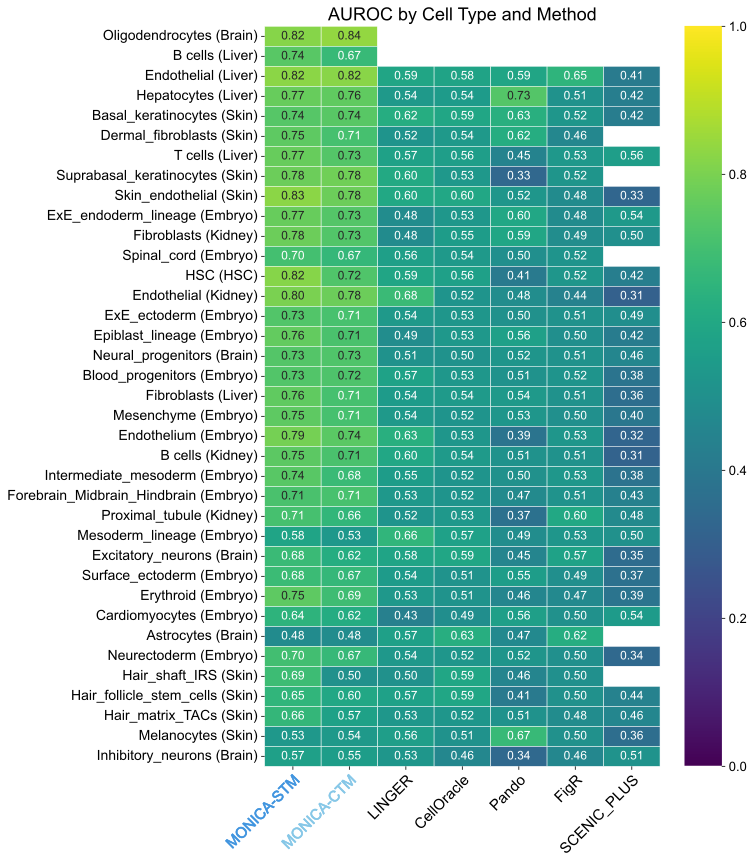

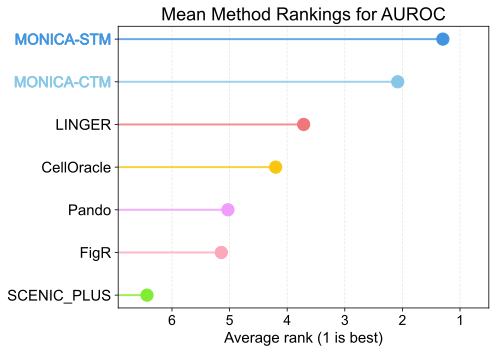

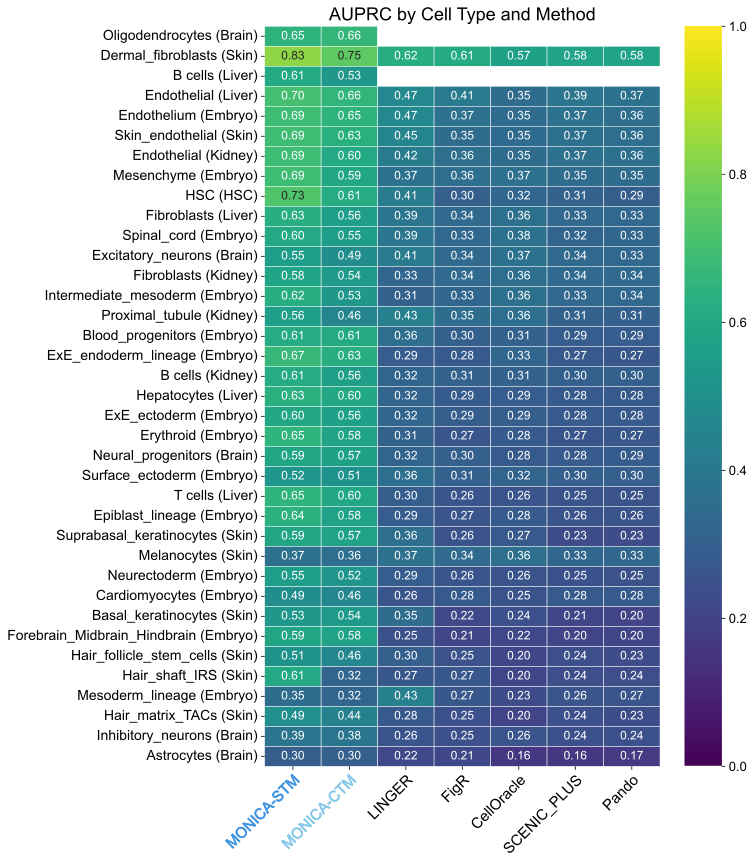

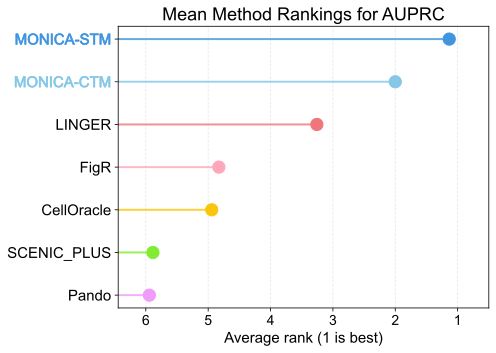

Saved per-model lollipop plots to /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/rank_plots/rank_lollipop_plots/<model_name>


,cell_type,tissue,method_name,auroc,rand_auroc,auprc,rand_auprc,early_precision,early_precision_rate,accuracy,...,top_tp,top_fp,top_fn,top_tn,n_universe_pairs,n_pos,n_neg,n_ground_truth_edges,ptf_alpha,panel
0,Astrocytes,Brain,CellOracle,0.628791,0.510936,0.159276,0.160288,0.266892,2.070689,0.837335,...,79.0,217.0,10014.0,52586.0,62896.0,381.0,2575.0,10093.0,0.05,Astrocytes (Brain)
1,Astrocytes,Brain,FigR,0.617829,0.476831,0.213405,0.159726,0.453953,2.279521,0.837955,...,488.0,587.0,9605.0,52216.0,62896.0,2141.0,8610.0,10093.0,0.05,Astrocytes (Brain)
2,Astrocytes,Brain,LINGER,0.566317,0.506725,0.218024,0.160207,0.257776,1.404377,0.803374,...,1210.0,3484.0,8883.0,49319.0,62896.0,8615.0,38320.0,10093.0,0.05,Astrocytes (Brain)
3,Astrocytes,Brain,TF-TG Model (cross-trained),0.483787,0.502448,0.296913,0.160192,0.121658,0.364973,0.803533,...,364.0,2628.0,9729.0,50175.0,62896.0,9975.0,19950.0,10093.0,0.05,Astrocytes (Brain)
4,Astrocytes,Brain,TF-TG Model (self-trained),0.476863,0.519427,0.296685,0.157733,0.182292,0.546875,0.810508,...,35.0,157.0,604.0,3220.0,4016.0,639.0,1278.0,639.0,0.05,Astrocytes (Brain)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244,T cells,Liver,LINGER,0.571944,0.500117,0.295986,0.254604,0.394621,1.476858,0.735472,...,16140.0,24760.0,205011.0,622697.0,868608.0,109285.0,299711.0,221151.0,0.05,T cells (Liver)
245,T cells,Liver,CellOracle,0.556363,0.501658,0.264509,0.255394,0.385217,1.299544,0.744213,...,1725.0,2753.0,219426.0,644704.0,868608.0,13273.0,31504.0,221151.0,0.05,T cells (Liver)
246,T cells,Liver,SCENIC_PLUS,0.555556,1.000000,0.254532,0.255466,0.000000,0.000000,0.745391,...,0.0,4.0,221151.0,647453.0,868608.0,3.0,36.0,221151.0,0.05,T cells (Liver)
247,T cells,Liver,FigR,0.531884,0.499887,0.260136,0.255401,0.334284,1.282110,0.741649,...,3283.0,6538.0,217868.0,640919.0,868608.0,25607.0,72606.0,221151.0,0.05,T cells (Liver)


Saved comparison plots and metrics to /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots


In [ ]:
import math

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve

metric_name_map = {
    "auroc": "AUROC",
    "auprc": "AUPRC",
    "accuracy": "Accuracy",
    "early_precision": "Early Precision",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}

sample_tissue_map = {
    "E7.5_rep1": "Embryo", 
    "E7.5_rep2": "Embryo",
    "E8.0_rep1": "Embryo", 
    "E8.0_rep2": "Embryo",
    "E8.5_rep1": "Embryo", 
    "E8.5_rep2": "Embryo",
    "Ctrl_4weeks_1": "Kidney", 
    "Ctrl_4weeks_2": "Kidney", 
    "Ctrl_6months_1": "Kidney",
    "skin_late_anagen": "Skin",
    "shareseq_brain": "Brain", 
    "E18_brain": "Brain",
    "young_rep1": "HSC", 
    "young_rep2": "HSC", 
    "old_rep1": "HSC", 
    "old_rep2": "HSC",
    "liver_sample": "Liver",
}

group_by_self_vs_eval = False

comparison_plot_dir = (
    PROJECT_DIR / "new_plots"
)
comparison_plot_dir.mkdir(parents=True, exist_ok=True)

def summarize_by_cell_type(metric_df):
    """Average each method's metrics over the samples that contain the cell type."""
    metric_df = metric_df.copy()
    metric_df["tissue"] = metric_df["sample_name"].map(sample_tissue_map)
    unmapped = sorted(metric_df.loc[metric_df["tissue"].isna(), "sample_name"].unique())
    if unmapped:
        raise ValueError(f"No tissue in sample_tissue_map for: {unmapped}")

    numeric_cols = metric_df.select_dtypes("number").columns
    metric_df = (
        metric_df.groupby(["cell_type", "tissue", "method_name"], as_index=False)[numeric_cols].mean()
    )
    metric_df["panel"] = metric_df["cell_type"] + " (" + metric_df["tissue"] + ")"
    return metric_df


comparison_metric_df = summarize_by_cell_type(celltype_metrics_df)

# Set method order: TF-TG models first, then the other methods.
available_methods = sorted(comparison_metric_df["method_name"].unique())
model_methods = [m for m in (SELF_MODEL_METHOD, CROSS_MODEL_METHOD) if m in available_methods]
method_order = model_methods + [m for m in available_methods if m not in model_methods]
fallback_colors = sns.color_palette("tab10", n_colors=max(len(method_order), 1))
for index, method in enumerate(method_order):
    method_color_dict.setdefault(method, fallback_colors[index])

all_comparison_figures = {}


def _display_method_name(method_name):
    return method_display_name_map.get(method_name, method_name)


def plot_cell_type_curve_panels(curve_kind, ncols=3):
    """
    One panel per (sample, cell type). Curves use the same samples as the
    metrics: ROC on the 1:1 predicted-edge sample, PR on the universe sample
    (unpredicted pairs scored 0, 10x negatives).
    """
    panels = list(
        comparison_metric_df[["sample_name", "cell_type", "panel"]]
        .drop_duplicates()
        .sort_values(["sample_name", "cell_type"])
        .itertuples(index=False)
    )
    nrows = math.ceil(len(panels) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(5.2 * ncols, 4.5 * nrows), squeeze=False,
    )

    metric_column = "auroc" if curve_kind == "roc" else "auprc"
    for ax, (sample_name, cell_type, panel) in zip(axes.flat, panels):
        cell_metrics = comparison_metric_df[comparison_metric_df["panel"] == panel]
        plotted_methods = (
            cell_metrics.sort_values(metric_column, ascending=False)["method_name"].tolist()
        )
        positive_fraction = None
        for method_name in plotted_methods:
            curves = curve_data.get((sample_name, cell_type, method_name))
            if curves is None:
                continue

            if curve_kind == "roc":
                labels, scores = curves["roc_labels"], curves["roc_scores"]
            else:
                labels, scores = curves["pr_labels"], curves["pr_scores"]
            if len(np.unique(labels)) < 2:
                continue

            if curve_kind == "roc":
                x_values, y_values, _ = roc_curve(labels, scores)
            else:
                precision, recall, _ = precision_recall_curve(labels, scores)
                positive_fraction = float(labels.mean())
                x_values = recall
                y_values = precision / positive_fraction if curve_kind == "prc_lift" else precision

            ax.plot(
                x_values, y_values,
                color=method_color_dict[method_name],
                linewidth=3 if method_name in model_methods else 1.8,
            )

        if curve_kind == "roc":
            ax.plot([0, 1], [0, 1], color="black", linestyle="--", alpha=0.5)
            ax.set_ylim(0, 1)
        elif curve_kind == "prc":
            # Every method in a panel shares one universe sample, so one baseline.
            if positive_fraction is not None:
                ax.axhline(positive_fraction, color="black", linestyle="--", alpha=0.5)
            ax.set_ylim(0, 1)
        else:
            ax.axhline(1, color="black", linestyle="--", alpha=0.5)
        ax.set_xlim(0, 1)

        ax.set_title(panel)
        ax.grid(linestyle="--", alpha=0.25)

    for ax in axes.flat[len(panels):]:
        ax.set_visible(False)

    title_by_kind = {
        "roc": "ROC Curves by Cell Type (1:1 predicted edges)",
        "prc": "Precision-Recall Curves by Cell Type (1:10 universe sample)",
        "prc_lift": "Precision-Recall Lift Curves by Cell Type",
    }
    y_label_by_kind = {
        "roc": "True Positive Rate",
        "prc": "Precision",
        "prc_lift": "Precision / Positive Fraction",
    }
    fig.suptitle(title_by_kind[curve_kind], fontsize=18)
    fig.supxlabel("False Positive Rate" if curve_kind == "roc" else "Recall")
    fig.supylabel(y_label_by_kind[curve_kind])

    legend_handles = [
        Line2D(
            [0], [0], color=method_color_dict[method],
            linewidth=3 if method in model_methods else 1.8,
            label=_display_method_name(method),
        )
        for method in method_order
    ]
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    # Legend below the axis label; savefig(bbox_inches="tight") keeps it in the image.
    fig.legend(
        handles=legend_handles, loc="upper center", ncol=min(4, len(legend_handles)),
        bbox_to_anchor=(0.5, 0.0), frameon=False,
    )
    return fig, axes


# for curve_kind in ("roc", "prc", "prc_lift"):
#     fig, axes = plot_cell_type_curve_panels(curve_kind)
#     fig.savefig(
#         comparison_plot_dir / f"{curve_kind}_curves_by_cell_type.png",
#         dpi=300, bbox_inches="tight", facecolor="white",
#     )
#     all_comparison_figures[f"{curve_kind}_curves"] = (fig, axes)
#     plt.show()


import matplotlib as mpl
import matplotlib.patheffects as pe

# Custom font (arial_font is registered in the boxplot cell above).
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = [arial_font, "Helvetica", "Liberation Sans", "DejaVu Sans"]


def _style_method_ticklabels(ticklabels, methods, fontsize):
    """Color and embolden the MONICA labels, as in the boxplots."""
    for tick, method in zip(ticklabels, methods):
        tick.set_fontsize(fontsize)
        if method in model_methods:
            tick.set_color(method_color_dict.get(method, "black"))
            tick.set_path_effects([pe.withStroke(linewidth=0.6, foreground=tick.get_color())])
        else:
            tick.set_color("black")


def average_method_rank(metric_df, metric_name):
    """Rank the methods in each cell type panel, then average each method's rank."""
    rank_df = metric_df[["panel", "method_name", metric_name]].dropna().copy()
    rank_df["rank"] = (
        rank_df.groupby("panel")[metric_name]
        .rank(method="min", ascending=False)
    )
    average_rank = (
        rank_df.groupby("method_name", as_index=False)["rank"]
        .mean().rename(columns={"rank": "average_rank"})
        .sort_values("average_rank")
    )
    return rank_df, average_rank


def plot_rank_lollipop(average_rank, metric_name, title_suffix_str=""):
    ordered_methods = average_rank["method_name"].tolist()
    fig_rank, ax_rank = plt.subplots(figsize=(7, 5))
    y_positions = np.arange(len(average_rank))
    max_rank = max(float(average_rank["average_rank"].max()) + 0.5, 1.5)
    colors = [method_color_dict[method] for method in ordered_methods]
    ax_rank.hlines(
        y_positions, max_rank, average_rank["average_rank"],
        color=colors, linewidth=2, alpha=0.8,
    )
    ax_rank.scatter(
        average_rank["average_rank"], y_positions,
        color=colors, s=150, zorder=3,
    )
    ax_rank.set_yticks(y_positions)
    ax_rank.set_yticklabels([_display_method_name(method) for method in ordered_methods])
    _style_method_ticklabels(ax_rank.get_yticklabels(), ordered_methods, fontsize=15)
    ax_rank.tick_params(axis="x", labelsize=14)
    ax_rank.set_xlim(max_rank, 0.5)
    ax_rank.invert_yaxis()
    ax_rank.set_xlabel("Average rank (1 is best)", fontsize=15)
    ax_rank.set_title(f"Mean Method Rankings for {metric_name.upper()}{title_suffix_str}", fontsize=18)
    ax_rank.grid(axis="x", linestyle="--", alpha=0.3)
    fig_rank.tight_layout()
    return fig_rank, ax_rank


rank_lollipop_dir = comparison_plot_dir / "rank_plots" / "rank_lollipop_plots"

rank_summary = {}
for metric_name in ("auroc", "auprc"):
    rank_df, average_rank = average_method_rank(comparison_metric_df, metric_name)
    ordered_methods = average_rank["method_name"].tolist()

    metric_matrix = rank_df.pivot(
        index="panel", columns="method_name", values=metric_name,
    ).reindex(columns=ordered_methods)
    # Self-trained-only rows on top, then rows scored by both models, then cross-trained-only.
    panel_models = {
        panel: tuple(m for m in model_methods if m in row and pd.notna(row[m]))
        for panel, row in metric_matrix.iterrows()
    }
    group_order = {
        (SELF_MODEL_METHOD,): 0,
        (SELF_MODEL_METHOD, CROSS_MODEL_METHOD): 1,
        (CROSS_MODEL_METHOD,): 2,
    }
    
    if group_by_self_vs_eval:
        metric_matrix = metric_matrix.loc[sorted(
            metric_matrix.index,
            key=lambda panel: (group_order.get(panel_models[panel], len(group_order)), panel),
        )]
    else:
        metric_matrix = metric_matrix.loc[
            metric_matrix.mean(axis=1).sort_values(ascending=False).index
        ]

        
    # Label colour follows the first model that scored the row (self-trained for shared rows).
    panel_eval_type = {panel: models[0] if models else None for panel, models in panel_models.items()}
    fig_heatmap, ax_heatmap = plt.subplots(
        figsize=(1.25 * len(ordered_methods) + 2, 0.3 * len(metric_matrix) + 1),
    )
    sns.heatmap(
        metric_matrix, annot=True, fmt=".2f", cmap="viridis",
        vmin=0, vmax=1, linewidths=0.5, linecolor="white", ax=ax_heatmap,
        annot_kws={"fontsize": 12},
    )
    ax_heatmap.set_xticklabels(
        [_display_method_name(method) for method in ordered_methods],
        rotation=45, ha="right", rotation_mode="anchor",
    )
    _style_method_ticklabels(ax_heatmap.get_xticklabels(), ordered_methods, fontsize=15)
    ax_heatmap.tick_params(axis="y", labelsize=14)

    ax_heatmap.collections[0].colorbar.ax.tick_params(labelsize=13)
    ax_heatmap.set_xlabel("")
    ax_heatmap.set_ylabel("")
    ax_heatmap.set_title(f"{metric_name.upper()} by Cell Type and Method", fontsize=18)
    fig_heatmap.tight_layout()
    fig_heatmap.savefig(
        comparison_plot_dir / "rank_plots" / "rank_heatmaps" / f"{metric_name}_method_heatmap.png",
        dpi=300, bbox_inches="tight", facecolor="white",
    )
    plt.show()

    fig_rank, ax_rank = plot_rank_lollipop(average_rank, metric_name)
    fig_rank.savefig(
        rank_lollipop_dir / f"average_{metric_name}_rank_lollipop.png",
        dpi=300, bbox_inches="tight", facecolor="white",
    )
    plt.show()

    rank_summary[metric_name] = {
        "rank_data": rank_df,
        "average_rank": average_rank,
        "heatmap": (fig_heatmap, ax_heatmap),
        "lollipop": (fig_rank, ax_rank),
    }

all_comparison_figures["rank_summary"] = rank_summary

# Each model on its own, against the other methods on the same (sample, cell type) pairs
model_rank_summary = {}
for model_name in model_run_dict:
    model_comparison_df = summarize_by_cell_type(metrics_for_model(model_name))
    model_lollipop_dir = rank_lollipop_dir / model_name
    model_lollipop_dir.mkdir(parents=True, exist_ok=True)
    for metric_name in ("auroc", "auprc"):
        _, model_average_rank = average_method_rank(model_comparison_df, metric_name)
        fig_rank, _ = plot_rank_lollipop(model_average_rank, metric_name, title_suffix_str=f"\n({model_name})")
        fig_rank.savefig(
            model_lollipop_dir / f"average_{metric_name}_rank_lollipop.png",
            dpi=300, bbox_inches="tight", facecolor="white",
        )
        plt.close(fig_rank)
        model_rank_summary[(model_name, metric_name)] = model_average_rank
print(f"Saved per-model lollipop plots to {rank_lollipop_dir}/<model_name>")
comparison_metric_df.to_csv(
    comparison_plot_dir / "comparison_metrics_by_cell_type.csv", index=False,
)
display(
    comparison_metric_df.sort_values(
        ["cell_type", "auroc"], ascending=[True, False],
    ).reset_index(drop=True)
)
print(f"Saved comparison plots and metrics to {comparison_plot_dir}")


In [ ]:
comparison_metric_df

,cell_type,tissue,method_name,auroc,rand_auroc,auprc,rand_auprc,early_precision,early_precision_rate,accuracy,...,top_tp,top_fp,top_fn,top_tn,n_universe_pairs,n_pos,n_neg,n_ground_truth_edges,ptf_alpha,panel
0,Astrocytes,Brain,CellOracle,0.628791,0.510936,0.159276,0.160288,0.266892,2.070689,0.837335,...,79.0,217.0,10014.0,52586.0,62896.0,381.0,2575.0,10093.0,0.05,Astrocytes (Brain)
1,Astrocytes,Brain,FigR,0.617829,0.476831,0.213405,0.159726,0.453953,2.279521,0.837955,...,488.0,587.0,9605.0,52216.0,62896.0,2141.0,8610.0,10093.0,0.05,Astrocytes (Brain)
2,Astrocytes,Brain,LINGER,0.566317,0.506725,0.218024,0.160207,0.257776,1.404377,0.803374,...,1210.0,3484.0,8883.0,49319.0,62896.0,8615.0,38320.0,10093.0,0.05,Astrocytes (Brain)
3,Astrocytes,Brain,Pando,0.472520,0.532197,0.174278,0.159845,0.275862,0.670450,0.839115,...,16.0,42.0,10077.0,52761.0,62896.0,237.0,339.0,10093.0,0.05,Astrocytes (Brain)
4,Astrocytes,Brain,SCENIC_PLUS,NaN,NaN,0.160111,0.160365,0.000000,NaN,0.839497,...,0.0,2.0,10093.0,52801.0,62896.0,0.0,21.0,10093.0,0.05,Astrocytes (Brain)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244,T cells,Liver,LINGER,0.571944,0.500117,0.295986,0.254604,0.394621,1.476858,0.735472,...,16140.0,24760.0,205011.0,622697.0,868608.0,109285.0,299711.0,221151.0,0.05,T cells (Liver)
245,T cells,Liver,Pando,0.448823,0.504542,0.254802,0.255431,0.239899,0.897073,0.745159,...,95.0,301.0,221056.0,647156.0,868608.0,1059.0,2901.0,221151.0,0.05,T cells (Liver)
246,T cells,Liver,SCENIC_PLUS,0.555556,1.000000,0.254532,0.255466,0.000000,0.000000,0.745391,...,0.0,4.0,221151.0,647453.0,868608.0,3.0,36.0,221151.0,0.05,T cells (Liver)
247,T cells,Liver,TF-TG Model (cross-trained),0.733717,0.499266,0.595606,0.254701,0.734674,2.204023,0.780724,...,48033.0,17347.0,173118.0,630110.0,868608.0,217932.0,435864.0,221151.0,0.05,T cells (Liver)


In [ ]:
comparison_metric_df_copy = comparison_metric_df.copy()
comparison_metric_df_copy = comparison_metric_df_copy[comparison_metric_df_copy["method_name"].isin([SELF_MODEL_METHOD, CROSS_MODEL_METHOD])]
comparison_metric_df_copy = comparison_metric_df_copy[["auroc", "n_tfs", "n_targets", "n_edges", "n_evaluable_tfs", "n_pos", "n_neg", "n_ground_truth_edges"]]
comparison_metric_df_copy

,auroc,n_tfs,n_targets,n_edges,n_evaluable_tfs,n_pos,n_neg,n_ground_truth_edges
5,0.483787,8.000000,7765.000000,29925.000000,7.000000,9975.000000,19950.000000,10093.000000
6,0.476863,8.000000,502.000000,1917.000000,7.000000,639.000000,1278.000000,639.000000
12,0.712104,43.666667,15201.333333,602891.333333,37.000000,201146.333333,401745.000000,204529.000000
13,0.748699,43.666667,959.666667,41222.333333,34.333333,13923.333333,27299.000000,13923.333333
14,0.673510,48.000000,16592.000000,735042.000000,35.000000,245190.000000,489852.000000,249215.000000
...,...,...,...,...,...,...,...,...
234,0.776218,11.000000,624.000000,4887.000000,5.000000,1629.000000,3258.000000,1629.000000
240,0.667866,12.833333,12032.000000,138919.500000,12.833333,46306.500000,92613.000000,46940.000000
241,0.680488,12.833333,831.000000,10223.000000,12.333333,3407.666667,6815.333333,3407.666667
247,0.733717,52.000000,16255.000000,653796.000000,41.000000,217932.000000,435864.000000,221151.000000


<Axes: xlabel='n_tfs', ylabel='auroc'>

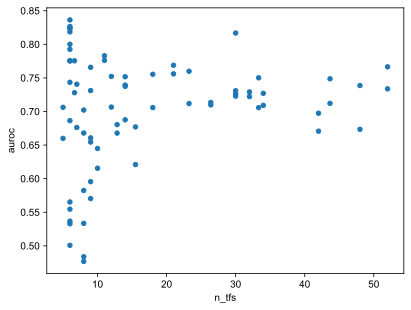

In [ ]:
comparison_metric_df_copy.plot.scatter(x="n_tfs", y="auroc")

### Do the different models agree on the edge scores?

In [ ]:
# A sample keeps its own name unless another tissue has a sample with the same
# name; then it becomes <tissue>__<sample>, as in holdout_grn_paths.
found = [
    (tissue_dir.name, path.parent.name, path)
    for tissue_dir in (data_dir / "processed").iterdir()
    for path in tissue_dir.rglob("*/multiome_processed.h5mu")
]
name_counts = Counter(sample for _, sample, _ in found)

sample_sources = {}   # unique ID -> where the sample's data is
for tissue, sample, path in found:
    uid = sample if name_counts[sample] == 1 else f"{tissue}__{sample}"
    sample_sources[uid] = {"tissue": tissue, "sample": sample, "h5mu": path}

# Create a (tissue, sample) map to the unique sample ID for each sample
uid_of = {(src["tissue"], src["sample"]): uid for uid, src in sample_sources.items()}

# Create a mapping from unique sample ID to tissue
sample_to_tissue_map = {uid: src["tissue"] for uid, src in sample_sources.items()}

# Runs trained before the 2026-10 rename still name both brain samples "brain".
RENAMED_SAMPLES = {
    ("GSE140203_shareseq", "brain"): "shareseq_brain",
    ("10x_E18_mouse_brain", "brain"): "E18_brain",
}

# Other-method GRN files use the renamed sample names, so no overrides are needed.
OTHER_METHOD_SAMPLE = {}

# Load and concatenate the self-trained and cross-trained GRNs for each model
model_self_grn_no_agg_list = []
model_cross_grn_no_agg_list = []
for model_name, run_name in model_run_dict.items():
    model_checkpoint = CHKPT_DIR / "celltype_tf_tg" / run_name / "checkpoints" / "last.ckpt"
    model_self_grn, model_cross_grn = load_grns_from_model_run(model_checkpoint, uid_of)

    model_self_grn["model_name"] = model_name
    model_cross_grn["model_name"] = model_name
    
    model_self_grn_no_agg_list.append(model_self_grn)
    model_cross_grn_no_agg_list.append(model_cross_grn)

self_trained_grn_no_agg = pd.concat(model_self_grn_no_agg_list, ignore_index=True)
evaluation_grn_no_agg = pd.concat(model_cross_grn_no_agg_list, ignore_index=True)

Self-trained GRN: 1,314,263 edges from ['Ctrl_4weeks_1', 'Ctrl_4weeks_2', 'Ctrl_6months_1', 'E18_brain', 'E7.5_rep1', 'E7.5_rep2', 'E8.0_rep1', 'E8.0_rep2', 'E8.5_rep1', 'E8.5_rep2', 'old_rep1', 'old_rep2', 'shareseq_brain', 'skin_late_anagen', 'young_rep1', 'young_rep2']
Cross-trained GRN: 1,990,467 edges from ['liver_sample']
Self-trained GRN: 530,722 edges from ['Ctrl_4weeks_1', 'Ctrl_4weeks_2', 'Ctrl_6months_1', 'E18_brain', 'liver_sample', 'old_rep1', 'old_rep2', 'shareseq_brain', 'skin_late_anagen', 'young_rep1', 'young_rep2']
Cross-trained GRN: 16,874,127 edges from ['E7.5_rep1', 'E7.5_rep2', 'E8.0_rep1', 'E8.0_rep2', 'E8.5_rep1', 'E8.5_rep2']
Self-trained GRN: 1,578,357 edges from ['Ctrl_4weeks_1', 'Ctrl_4weeks_2', 'Ctrl_6months_1', 'E7.5_rep1', 'E7.5_rep2', 'E8.0_rep1', 'E8.0_rep2', 'E8.5_rep1', 'E8.5_rep2', 'liver_sample', 'old_rep1', 'old_rep2', 'skin_late_anagen', 'young_rep1', 'young_rep2']
Cross-trained GRN: 938,809 edges from ['E18_brain', 'shareseq_brain']
Self-trained 

In [ ]:
self_trained_grn_no_agg.head()

,SampleID,CellType,Source,Target,Score,Label,model_name
0,E7.5_rep1,Neurectoderm,SOX2,LAMA3,0.346230,False,no_liver
1,E7.5_rep1,Mesoderm_lineage,ELK4,CCDC172,0.125809,False,no_liver
2,E7.5_rep1,Blood_progenitors,EBF1,MEX3C,0.179040,False,no_liver
3,E7.5_rep1,Blood_progenitors,LYL1,MPP7,0.390087,False,no_liver
4,E7.5_rep1,Surface_ectoderm,AHR,MEGF10,0.180154,False,no_liver


In [ ]:
self_trained_grn_no_agg_save = self_trained_grn_no_agg.copy()
self_trained_grn_no_agg_save["CellType"] = self_trained_grn_no_agg_save["CellType"].astype(str)
self_trained_grn_no_agg_save["Source"] = self_trained_grn_no_agg_save["Source"].astype(str)
self_trained_grn_no_agg_save["Target"] = self_trained_grn_no_agg_save["Target"].astype(str)
self_trained_grn_no_agg_save["model_name"] = self_trained_grn_no_agg_save["model_name"].astype(str)
self_trained_grn_no_agg_save["Score"] = self_trained_grn_no_agg_save["Score"].astype(np.float16)
self_trained_grn_no_agg_save["Label"] = self_trained_grn_no_agg_save["Label"].astype(bool)

self_trained_grn_no_agg_save.to_parquet(
    PROJECT_DIR / "new_testing_results"/ "multiple_model_edge_scores.parquet",
    engine="pyarrow",
    compression="snappy",
    index=None
    )

In [ ]:
# There is overlap in the samples and cell types for each model's self-trained GRN
# Aggregate to get a list of GRN scores for each edge, generated by each model
self_trained_grn_by_model = self_trained_grn_no_agg.groupby(["SampleID", "CellType", "Source", "Target"])["Score"].agg(list).reset_index()
self_trained_grn_by_model.head()

,SampleID,CellType,Source,Target,Score
0,Ctrl_4weeks_1,B cells,BACH1,1110059E24RIK,"[0.14372578, 0.09664849, 0.19232033, 0.17082886]"
1,Ctrl_4weeks_1,B cells,BACH1,1500015A07RIK,"[0.09293694, 0.054315038, 0.109662354, 0.09807..."
2,Ctrl_4weeks_1,B cells,BACH1,1500015L24RIK,"[0.13517113, 0.07571108, 0.18908384, 0.13501327]"
3,Ctrl_4weeks_1,B cells,BACH1,1700018L02RIK,"[0.080348976, 0.064675294, 0.12877916, 0.09693..."
4,Ctrl_4weeks_1,B cells,BACH1,1700039E22RIK,"[0.15935892, 0.07606044, 0.16678305, 0.13106921]"


## Foundation Model Testing